In [1]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

PyTorch: 2.14.1+cu126
CUDA available: True
OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 3.1.1


In [2]:
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA version:", torch.version.cuda)


GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.6


In [3]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "../datasets/mvtec_ad"
bottle_path = os.path.join(dataset_path, "bottle")
train_path = os.path.join(bottle_path, "train")
test_path = os.path.join(bottle_path, "test")
ground_truth_path = os.path.join(bottle_path, "ground_truth")

print("Dataset path:", os.path.abspath(dataset_path))
print("Bottle dataset:", os.path.exists(bottle_path))
print("Ground truth:", os.path.exists(ground_truth_path))

Dataset path: d:\VisionInspect-AI\datasets\mvtec_ad
Bottle dataset: True
Ground truth: True


In [11]:
categories = [
    item for item in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, item))
]

print("Actual categories:", categories)
print("Total categories:", len(categories))

Actual categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
Total categories: 15


CATEGORY: BOTTLE
Normal training images: 209

Test images:
broken_large: 20 images
broken_small: 22 images
contamination: 21 images
good: 20 images


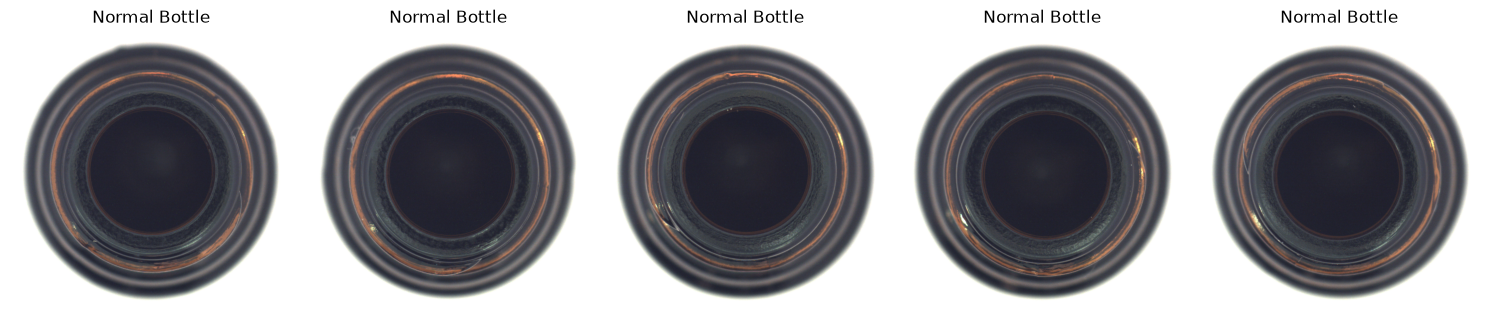

In [15]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset paths
bottle_path = os.path.join(dataset_path, "bottle")
train_path = os.path.join(bottle_path, "train")
test_path = os.path.join(bottle_path, "test")
ground_truth_path = os.path.join(bottle_path, "ground_truth")

# 1. Dataset structure
print("CATEGORY: BOTTLE")
# 2. Count training images
train_images = os.listdir(os.path.join(train_path, "good"))
print("Normal training images:", len(train_images))

# 3. Count test images by defect type
print("\nTest images:")
for defect in os.listdir(test_path):
    defect_path = os.path.join(test_path, defect)
    print(f"{defect}: {len(os.listdir(defect_path))} images")

# 4. Display sample normal images
sample_images = train_images[:5]

plt.figure(figsize=(15, 4))

for i, image_name in enumerate(sample_images):
    image_path = os.path.join(train_path, "good", image_name)
    image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title("Normal Bottle")
    plt.axis("off")

plt.tight_layout()
plt.show()

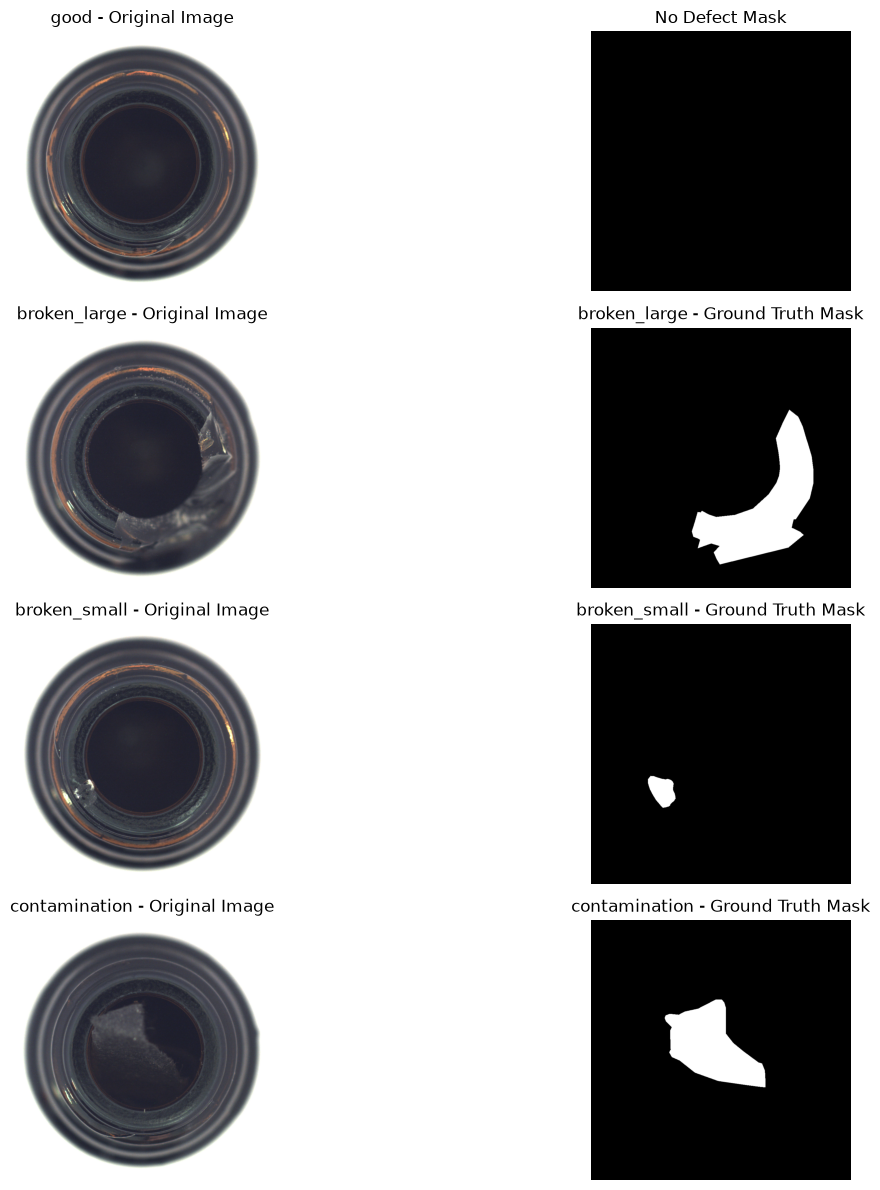

In [16]:
# Defect visualization

defect_types = ["good", "broken_large", "broken_small", "contamination"]

plt.figure(figsize=(15, 12))

for row, defect in enumerate(defect_types):
    folder_path = os.path.join(test_path, defect)
    image_name = os.listdir(folder_path)[0]

    image_path = os.path.join(folder_path, image_name)
    image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)

    plt.subplot(4, 2, row * 2 + 1)
    plt.imshow(image)
    plt.title(f"{defect} - Original Image")
    plt.axis("off")

    # Display corresponding ground-truth mask for defective images
    plt.subplot(4, 2, row * 2 + 2)

    if defect == "good":
        plt.imshow(np.zeros(image.shape[:2]), cmap="gray")
        plt.title("No Defect Mask")
    else:
        mask_path = os.path.join(
            ground_truth_path,
            defect,
            image_name.rsplit(".", 1)[0] + "_mask.png"
        )
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        plt.imshow(mask, cmap="gray")
        plt.title(f"{defect} - Ground Truth Mask")

    plt.axis("off")

plt.tight_layout()
plt.show()

IMAGE DATASET ANALYSIS
Total images analysed: 83

Image dimensions:
       Height  Width
count    83.0   83.0
mean    900.0  900.0
std       0.0    0.0
min     900.0  900.0
25%     900.0  900.0
50%     900.0  900.0
75%     900.0  900.0
max     900.0  900.0

Average brightness by defect type:
Defect_Type
broken_large     138.194500
broken_small     138.118182
contamination    139.316190
good             138.549000
Name: Mean_Brightness, dtype: float64


<Figure size 900x500 with 0 Axes>

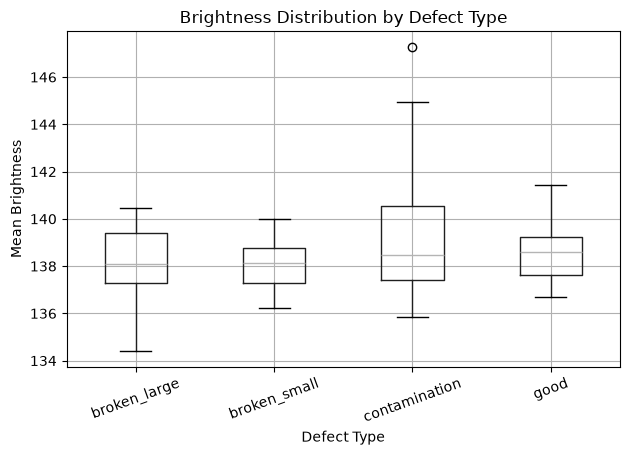

In [14]:
# Image dimensions and pixel analysis

image_records = []

for defect in os.listdir(test_path):
    folder_path = os.path.join(test_path, defect)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        image = cv2.imread(image_path)

        if image is not None:
            height, width, channels = image.shape

            image_records.append({
                "Defect_Type": defect,
                "Image": image_name,
                "Height": height,
                "Width": width,
                "Channels": channels,
                "Mean_Brightness": round(np.mean(image), 2)
            })

df = pd.DataFrame(image_records)

print("IMAGE DATASET ANALYSIS")
print("Total images analysed:", len(df))
print("\nImage dimensions:")
print(df[["Height", "Width"]].describe())

print("\nAverage brightness by defect type:")
print(df.groupby("Defect_Type")["Mean_Brightness"].mean())

# Visualize brightness distribution
plt.figure(figsize=(9, 5))
df.boxplot(column="Mean_Brightness", by="Defect_Type")
plt.title("Brightness Distribution by Defect Type")
plt.suptitle("")
plt.xlabel("Defect Type")
plt.ylabel("Mean Brightness")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

GROUND TRUTH MASK ANALYSIS
Total masks analysed: 63

Average defect coverage:
Defect Type
broken_large     11.702500
broken_small      3.068318
contamination     8.490143
Name: Defect Coverage (%), dtype: float64

Detailed statistics:


,count,mean,std,min,25%,50%,75%,max
Defect Type,,,,,,,,
broken_large,20.0,11.702500,5.274367,4.090,8.73700,11.8670,14.23175,27.419
broken_small,22.0,3.068318,1.917033,0.885,1.86975,2.4375,3.43275,8.061
contamination,21.0,8.490143,5.684683,0.576,3.33500,7.2480,14.91100,16.528


<Figure size 900x500 with 0 Axes>

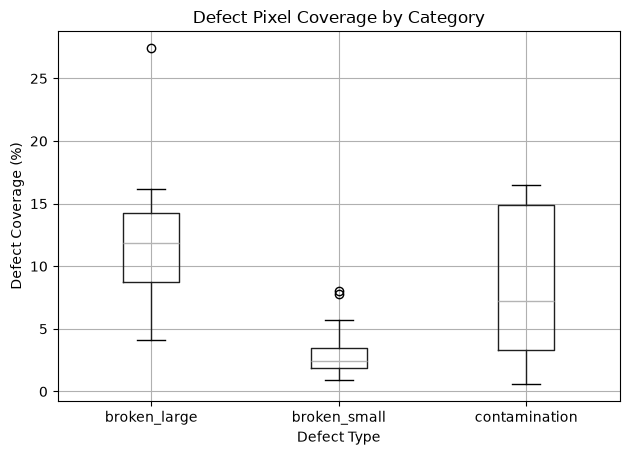

In [15]:
# GROUND TRUTH MASK ANALYSIS

mask_records = []

defect_types = ["broken_large", "broken_small", "contamination"]

for defect in defect_types:

    mask_folder = os.path.join(ground_truth_path, defect)

    for filename in os.listdir(mask_folder):

        mask_path = os.path.join(mask_folder, filename)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if mask is not None:
            total_pixels = mask.size
            defect_pixels = np.count_nonzero(mask > 0)

            defect_percentage = (defect_pixels / total_pixels) * 100

            mask_records.append({
                "Defect Type": defect,
                "Image": filename,
                "Defect Pixels": defect_pixels,
                "Total Pixels": total_pixels,
                "Defect Coverage (%)": round(defect_percentage, 3)
            })

# Convert results into DataFrame
mask_df = pd.DataFrame(mask_records)

print("GROUND TRUTH MASK ANALYSIS")
print("Total masks analysed:", len(mask_df))

print("\nAverage defect coverage:")
print(mask_df.groupby("Defect Type")["Defect Coverage (%)"].mean())

print("\nDetailed statistics:")
display(mask_df.groupby("Defect Type")["Defect Coverage (%)"].describe())

# Visualize defect coverage
plt.figure(figsize=(9, 5))

mask_df.boxplot(
    column="Defect Coverage (%)",
    by="Defect Type"
)

plt.title("Defect Pixel Coverage by Category")
plt.suptitle("")
plt.ylabel("Defect Coverage (%)")
plt.xlabel("Defect Type")
plt.tight_layout()
plt.show()

In [16]:
# U-NET: IMAGE AND MASK VERIFICATION

defect_types = ["broken_large", "broken_small", "contamination"]

for defect in defect_types:

    image_folder = os.path.join(test_path, defect)
    mask_folder = os.path.join(ground_truth_path, defect)

    images = [
        f for f in os.listdir(image_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    masks = [
        f for f in os.listdir(mask_folder)
        if f.endswith("_mask.png")
    ]

    image_names = {os.path.splitext(f)[0] for f in images}
    mask_names = {f.replace("_mask.png", "") for f in masks}

    matched = image_names & mask_names

    print(f"\nDEFECT: {defect}")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Matched pairs:", len(matched))
    print("Unmatched images:", len(image_names - mask_names))

print("\nVerification completed!")


DEFECT: broken_large
Images: 20
Masks: 20
Matched pairs: 20
Unmatched images: 0

DEFECT: broken_small
Images: 22
Masks: 22
Matched pairs: 22
Unmatched images: 0

DEFECT: contamination
Images: 21
Masks: 21
Matched pairs: 21
Unmatched images: 0

Verification completed!


In [24]:
# U-NET: IMAGE AND MASK PREPROCESSING

IMAGE_SIZE = 256

X = []
Y = []

defect_types = ["broken_large", "broken_small", "contamination"]

for defect in defect_types:

    image_folder = os.path.join(test_path, defect)
    mask_folder = os.path.join(ground_truth_path, defect)

    for filename in sorted(os.listdir(image_folder)):

        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        image_path = os.path.join(image_folder, filename)

        mask_name = os.path.splitext(filename)[0] + "_mask.png"
        mask_path = os.path.join(mask_folder, mask_name)

        # Load original image
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Load ground truth mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Resize image and mask
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        mask = cv2.resize(
            mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # Normalize image and convert mask to binary
        image = image.astype(np.float32) / 255.0
        mask = (mask > 0).astype(np.float32)

        X.append(image)
        Y.append(mask)

# Convert to NumPy arrays
X = np.array(X)
Y = np.array(Y)[..., np.newaxis]

print("PREPROCESSING COMPLETED")
print("Image dataset shape:", X.shape)
print("Mask dataset shape:", Y.shape)
print("Image pixel range:", X.min(), "to", X.max())
print("Mask values:", np.unique(Y))


PREPROCESSING COMPLETED
Image dataset shape: (63, 256, 256, 3)
Mask dataset shape: (63, 256, 256, 1)
Image pixel range: 0.09803922 to 1.0
Mask values: [0. 1.]


       U-NET DATASET VERIFICATION

1. DATASET SHAPES
Images: (63, 256, 256, 3)
Masks: (63, 256, 256, 1)

2. DATA TYPES
Image dtype: float32
Mask dtype: float32

3. PIXEL VALUE CHECK
Image range: 0.09803922 to 1.0
Mask values: [0. 1.]

4. DATA QUALITY
Missing image values: 0
Missing mask values: 0
Infinite image values: 0

5. DEFECT PIXEL DISTRIBUTION
Background pixels: 3814257
Defect pixels: 314511
Total defect coverage: 7.62 %


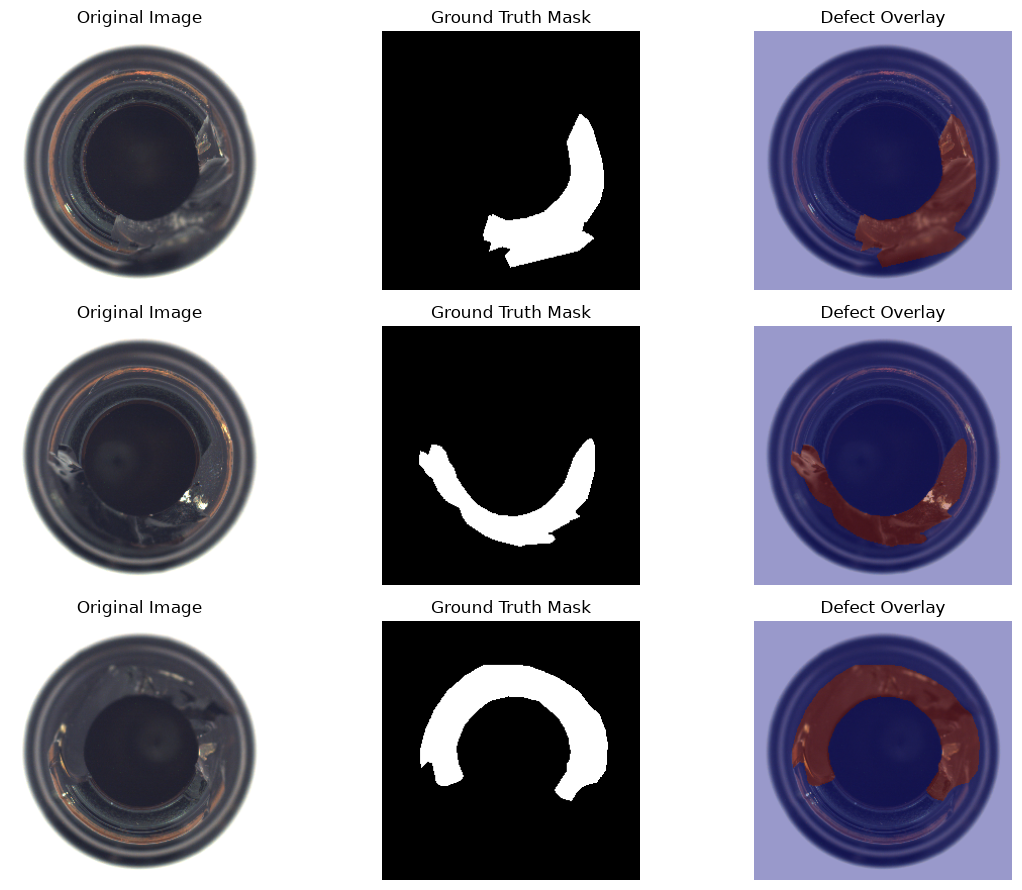


VERIFICATION COMPLETED!


In [25]:
# COMPLETE U-NET DATA VERIFICATION

print("       U-NET DATASET VERIFICATION")

# 1. Dataset shape
print("\n1. DATASET SHAPES")
print("Images:", X.shape)
print("Masks:", Y.shape)

# 2. Data types
print("\n2. DATA TYPES")
print("Image dtype:", X.dtype)
print("Mask dtype:", Y.dtype)

# 3. Pixel values
print("\n3. PIXEL VALUE CHECK")
print("Image range:", X.min(), "to", X.max())
print("Mask values:", np.unique(Y))

# 4. Missing or invalid values
print("\n4. DATA QUALITY")
print("Missing image values:", np.isnan(X).sum())
print("Missing mask values:", np.isnan(Y).sum())
print("Infinite image values:", np.isinf(X).sum())

# 5. Defect pixel distribution
print("\n5. DEFECT PIXEL DISTRIBUTION")
print("Background pixels:", np.sum(Y == 0))
print("Defect pixels:", np.sum(Y == 1))
print("Total defect coverage:", round(np.mean(Y) * 100, 2), "%")

# 6. Visual verification
plt.figure(figsize=(12, 9))

for i in range(3):
    plt.subplot(3, 3, i*3 + 1)
    plt.imshow(X[i])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(3, 3, i*3 + 2)
    plt.imshow(Y[i].squeeze(), cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(3, 3, i*3 + 3)
    plt.imshow(X[i])
    plt.imshow(Y[i].squeeze(), cmap="jet", alpha=0.4)
    plt.title("Defect Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nVERIFICATION COMPLETED!")

In [26]:
# U-NET: TRAINING AND VALIDATION SETUP

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Defect labels corresponding to X and Y
labels = np.array(
    ["broken_large"] * 20 +
    ["broken_small"] * 22 +
    ["contamination"] * 21
)

# Split dataset (80% training, 20% validation)
X_train, X_val, Y_train, Y_val = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Convert images from NHWC to NCHW for PyTorch
X_train = torch.tensor(
    X_train.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

X_val = torch.tensor(
    X_val.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

Y_train = torch.tensor(
    Y_train.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

Y_val = torch.tensor(
    Y_val.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

# Create datasets and loaders
train_dataset = TensorDataset(X_train, Y_train)
val_dataset = TensorDataset(X_val, Y_val)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False
)

print("\nDATA PREPARATION COMPLETED")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Image tensor shape:", X_train.shape)
print("Mask tensor shape:", Y_train.shape)

Device: cuda

DATA PREPARATION COMPLETED
Training samples: 50
Validation samples: 13
Training batches: 13
Validation batches: 4
Image tensor shape: torch.Size([50, 3, 256, 256])
Mask tensor shape: torch.Size([50, 1, 256, 256])


In [19]:
# U-NET ARCHITECTURE USING PYTORCH

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.enc4 = DoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec4 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        # Final segmentation output
        self.output = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)


# Initialize model
model = UNet().to(device)

# Count trainable parameters
parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

# Test model output shape
sample_input = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("U-NET MODEL CREATED")
print("Device:", device)
print("Trainable parameters:", f"{parameters:,}")
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

U-NET MODEL CREATED
Device: cuda
Trainable parameters: 1,944,049
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])


In [27]:
# U-NET: LOSS FUNCTION AND OPTIMIZER

# Binary Cross Entropy with Logits
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(predictions, targets, smooth=1e-6):

    predictions = torch.sigmoid(predictions)

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()

    dice = (2.0 * intersection + smooth) / (
        predictions.sum() + targets.sum() + smooth
    )

    return 1 - dice


# Combined BCE + Dice Loss
def combined_loss(predictions, targets):

    loss_bce = bce_loss(predictions, targets)
    loss_dice = dice_loss(predictions, targets)

    return 0.5 * loss_bce + 0.5 * loss_dice


# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 30

print("TRAINING CONFIGURATION")
print("Model: U-Net")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: BCE + Dice Loss")
print("Epochs:", EPOCHS)
print("Device:", device)

print("\nConfiguration completed!")

TRAINING CONFIGURATION
Model: U-Net
Optimizer: Adam
Learning rate: 0.001
Loss: BCE + Dice Loss
Epochs: 30
Device: cuda

Configuration completed!


In [28]:
# U-NET TRAINING LOOP

train_losses = []
val_losses = []
val_dice_scores = []

for epoch in range(EPOCHS):

    # Training
    model.train()
    running_train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = combined_loss(predictions, masks)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)

    # Validation
    model.eval()
    running_val_loss = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            predictions = model(images)
            loss = combined_loss(predictions, masks)

            probabilities = torch.sigmoid(predictions)
            predicted_masks = (probabilities > 0.5).float()

            intersection = (predicted_masks * masks).sum()
            dice = (2 * intersection + 1e-6) / (
                predicted_masks.sum() + masks.sum() + 1e-6
            )

            running_val_loss += loss.item()
            running_dice += dice.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_dice = running_dice / len(val_loader)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    val_dice_scores.append(epoch_val_dice)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Dice: {epoch_val_dice:.4f}"
    )

print("\nU-NET TRAINING COMPLETED!")

Epoch [1/30] Train Loss: 0.6990 | Val Loss: 0.7404 | Val Dice: 0.0009
Epoch [2/30] Train Loss: 0.6398 | Val Loss: 5.0932 | Val Dice: 0.1256
Epoch [3/30] Train Loss: 0.5961 | Val Loss: 3.3747 | Val Dice: 0.1482
Epoch [4/30] Train Loss: 0.5650 | Val Loss: 0.7391 | Val Dice: 0.2986
Epoch [5/30] Train Loss: 0.5325 | Val Loss: 0.8601 | Val Dice: 0.3014
Epoch [6/30] Train Loss: 0.4976 | Val Loss: 0.8060 | Val Dice: 0.3031
Epoch [7/30] Train Loss: 0.4876 | Val Loss: 0.4743 | Val Dice: 0.5825
Epoch [8/30] Train Loss: 0.4557 | Val Loss: 0.5031 | Val Dice: 0.5310
Epoch [9/30] Train Loss: 0.4337 | Val Loss: 0.8371 | Val Dice: 0.2676
Epoch [10/30] Train Loss: 0.4148 | Val Loss: 0.4283 | Val Dice: 0.6140
Epoch [11/30] Train Loss: 0.3994 | Val Loss: 0.4887 | Val Dice: 0.4200
Epoch [12/30] Train Loss: 0.3693 | Val Loss: 0.3789 | Val Dice: 0.7090
Epoch [13/30] Train Loss: 0.3622 | Val Loss: 0.4647 | Val Dice: 0.4425
Epoch [14/30] Train Loss: 0.3435 | Val Loss: 0.6565 | Val Dice: 0.2927
Epoch [15/30] T

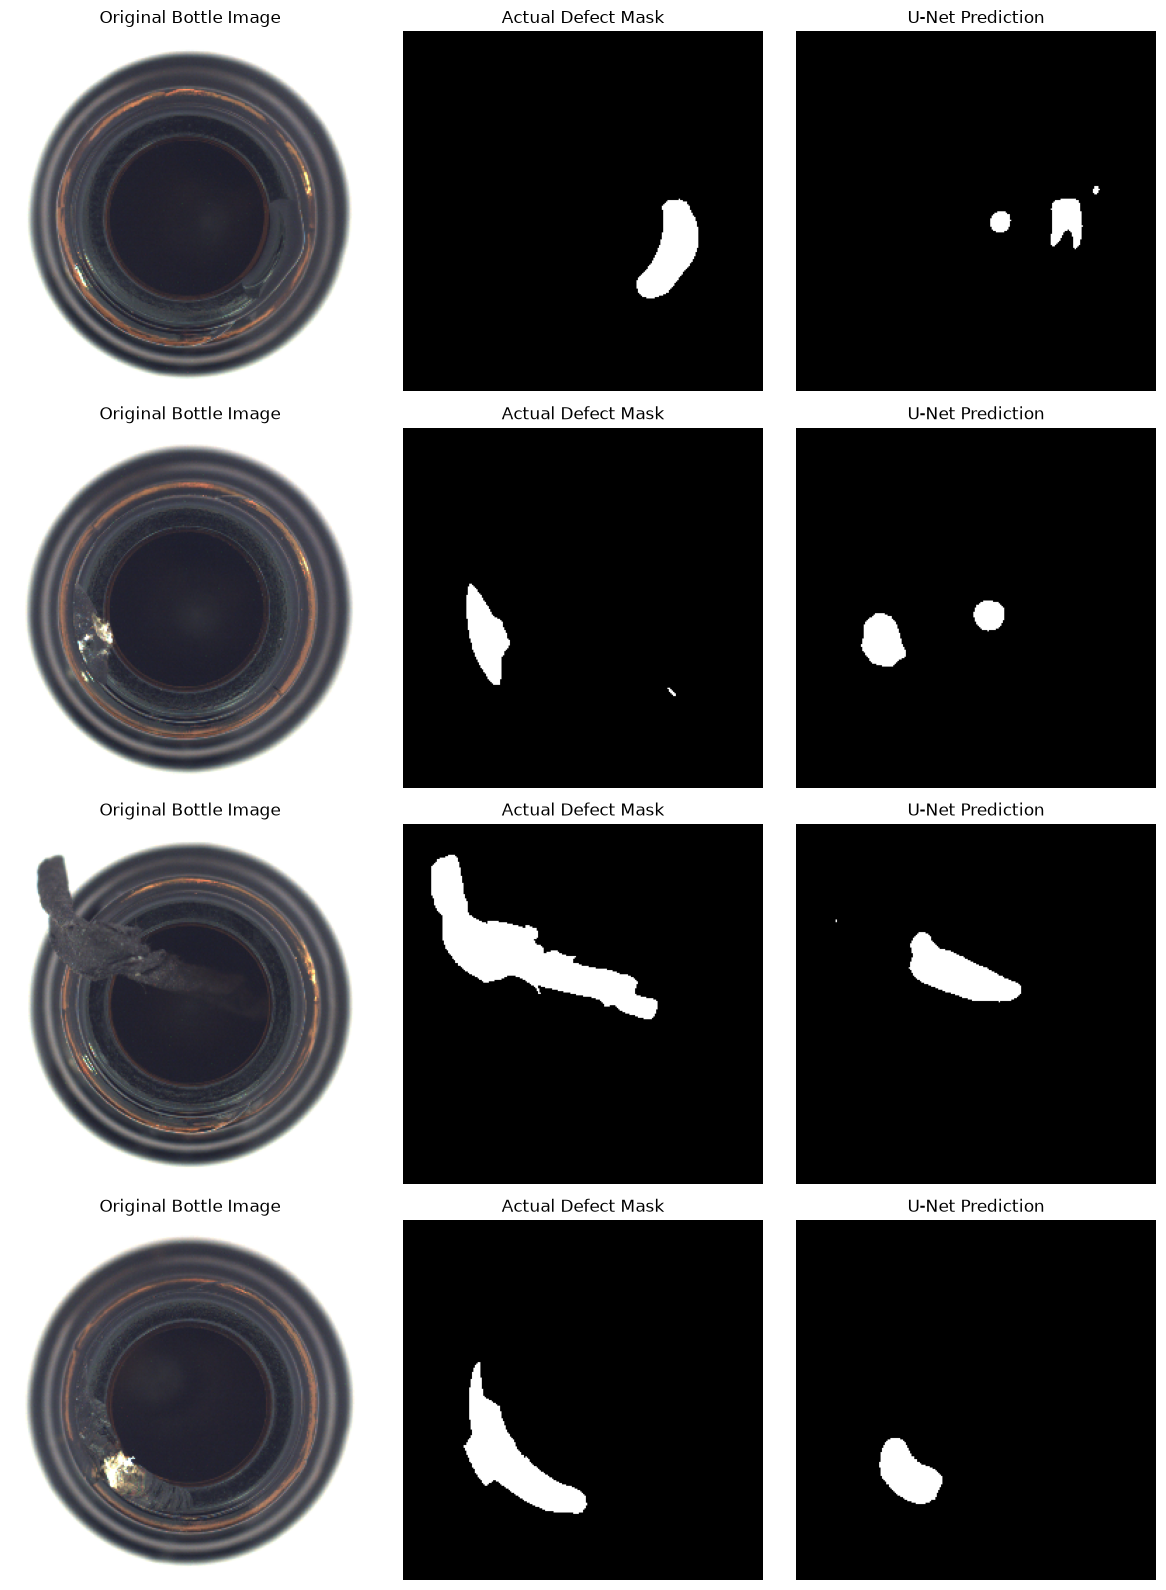

In [ ]:

# U-NET PREDICTION VISUALIZATION

model.eval()

images, masks = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    predictions = model(images)
    predictions = torch.sigmoid(predictions)
    predicted_masks = (predictions > 0.5).float()

images = images.cpu().numpy()
masks = masks.numpy()
predicted_masks = predicted_masks.cpu().numpy()

num_images = min(4, len(images))

fig, axes = plt.subplots(num_images, 3, figsize=(12, 4 * num_images))

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_images):
    axes[i, 0].imshow(np.transpose(images[i], (1, 2, 0)))
    axes[i, 0].set_title("Original Bottle Image")

    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Actual Defect Mask")

    axes[i, 2].imshow(predicted_masks[i, 0], cmap="gray")
    axes[i, 2].set_title("U-Net Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


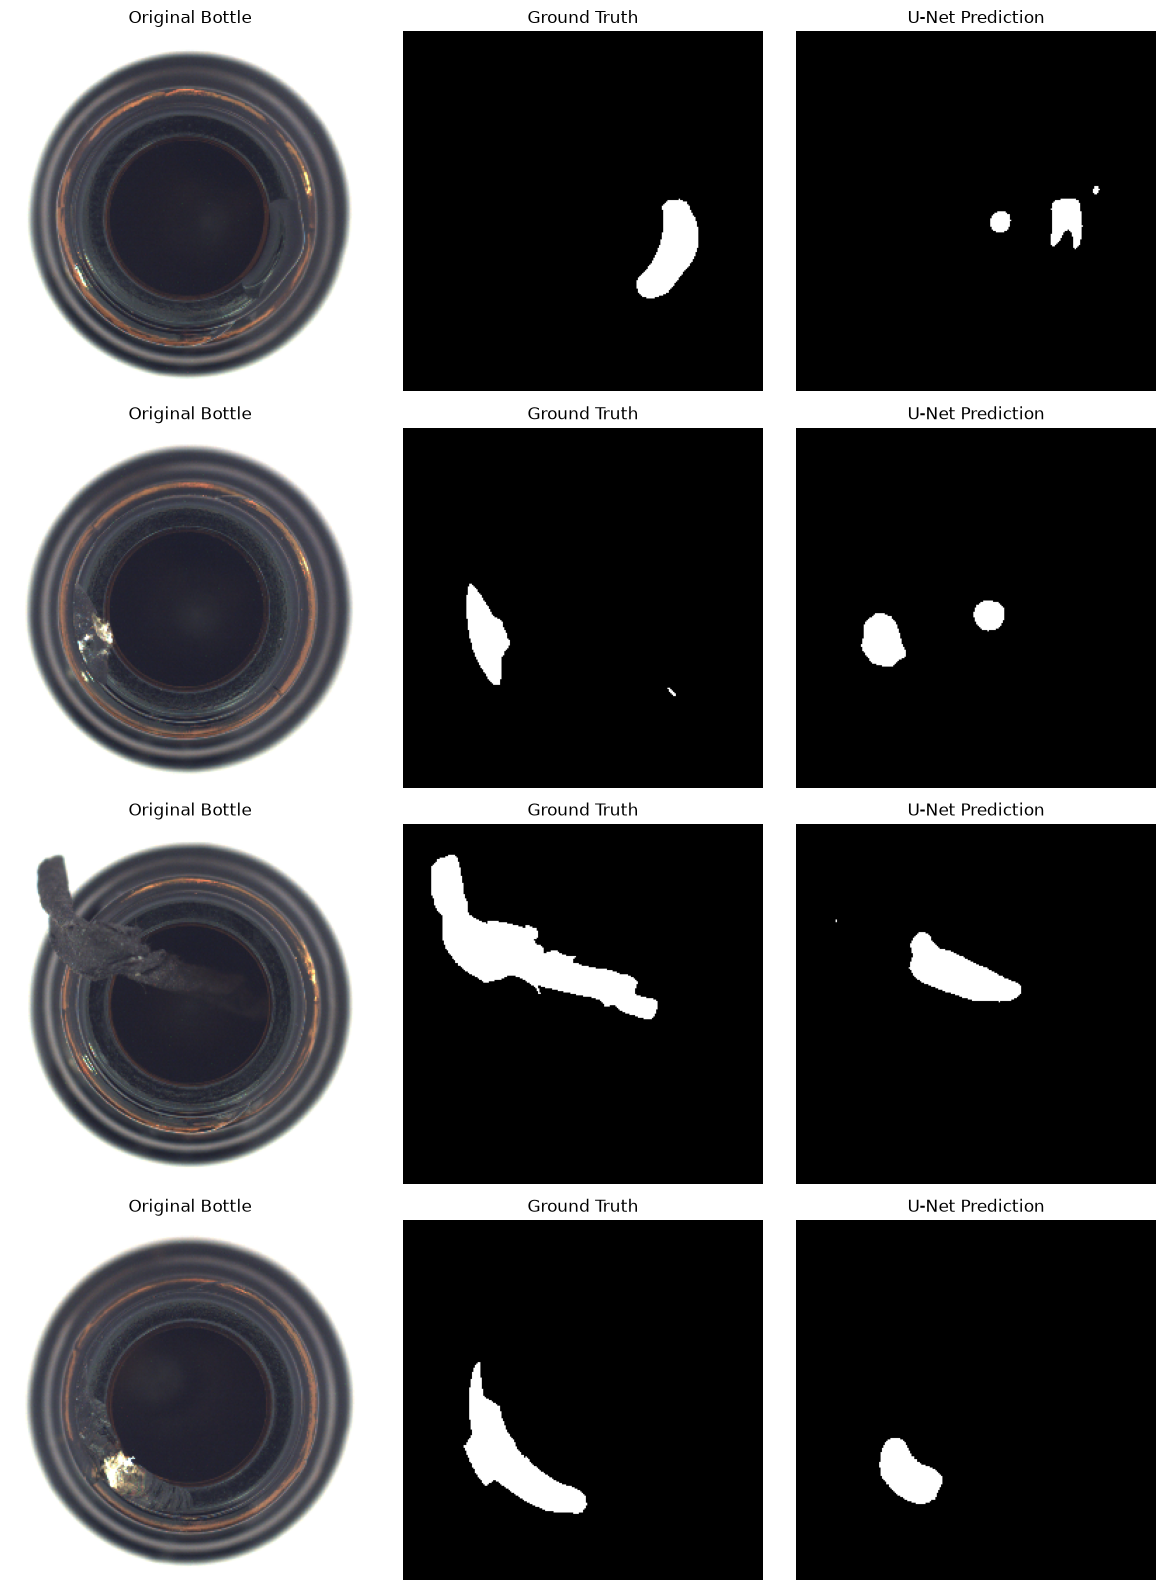

In [ ]:

# BOTTLE - U-NET PREDICTION VISUALIZATION

model.eval()

images, masks = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    predictions = model(images)
    predictions = torch.sigmoid(predictions)
    predicted_masks = (predictions > 0.5).float()

images = images.cpu().numpy()
masks = masks.numpy()
predicted_masks = predicted_masks.cpu().numpy()

num_images = min(4, len(images))

fig, axes = plt.subplots(num_images, 3, figsize=(12, 4 * num_images))

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_images):
    axes[i, 0].imshow(np.transpose(images[i], (1, 2, 0)))
    axes[i, 0].set_title("Original Bottle")

    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(predicted_masks[i, 0], cmap="gray")
    axes[i, 2].set_title("U-Net Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# BOTTLE - MODEL EVALUATION METRICS

model.eval()

total_tp = 0
total_fp = 0
total_fn = 0
total_intersection = 0
total_union = 0

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)

        predictions = model(images)
        probabilities = torch.sigmoid(predictions)
        predicted_masks = (probabilities > 0.5).float()

        tp = (predicted_masks * masks).sum().item()
        fp = (predicted_masks * (1 - masks)).sum().item()
        fn = ((1 - predicted_masks) * masks).sum().item()

        total_tp += tp
        total_fp += fp
        total_fn += fn

        total_intersection += tp
        total_union += tp + fp + fn

epsilon = 1e-7

dice = (2 * total_tp) / (2 * total_tp + total_fp + total_fn + epsilon)
iou = total_intersection / (total_union + epsilon)
precision = total_tp / (total_tp + total_fp + epsilon)
recall = total_tp / (total_tp + total_fn + epsilon)

print("BOTTLE U-NET EVALUATION RESULTS")
print("--------------------------------")
print(f"Dice Score : {dice:.4f}")
print(f"IoU Score  : {iou:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")


BOTTLE U-NET EVALUATION RESULTS
--------------------------------
Dice Score : 0.8078
IoU Score  : 0.6775
Precision  : 0.8925
Recall     : 0.7377


In [ ]:

# SAVE BOTTLE MODEL AND EVALUATION RESULTS

import os
import json
import torch

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save trained model
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": EPOCHS,
    "image_size": 256,
    "threshold": 0.5,
    "category": "bottle",
    "evaluation_metrics": {
        "dice": 0.8078,
        "iou": 0.6775,
        "precision": 0.8925,
        "recall": 0.7377
    }
}, "../models/bottle_unet.pth")

# Save evaluation report
results = {
    "category": "bottle",
    "model": "U-Net",
    "epochs": EPOCHS,
    "dice": 0.8078,
    "iou": 0.6775,
    "precision": 0.8925,
    "recall": 0.7377
}

with open("../models/bottle_evaluation.json", "w") as file:
    json.dump(results, file, indent=4)

print("BOTTLE MODEL SAVED SUCCESSFULLY!")
print("Model:", os.path.abspath("../models/bottle_unet.pth"))
print("Report:", os.path.abspath("../models/bottle_evaluation.json"))


BOTTLE MODEL SAVED SUCCESSFULLY!
Model: d:\VisionInspect-AI\models\bottle_unet.pth
Report: d:\VisionInspect-AI\models\bottle_evaluation.json


In [ ]:

# SCREW DATASET EXPLORATION

screw_path = os.path.join(dataset_path, "screw")

screw_train_path = os.path.join(screw_path, "train")
screw_test_path = os.path.join(screw_path, "test")
screw_ground_truth_path = os.path.join(screw_path, "ground_truth")

print("SCREW DATASET STRUCTURE")
print("-" * 40)

print("\nNormal training images:")
print(len(os.listdir(os.path.join(screw_train_path, "good"))))

print("\nScrew defect categories:")
screw_defect_types = [
    d for d in os.listdir(screw_test_path)
    if d != "good"
]

for defect in sorted(screw_defect_types):
    image_count = len(os.listdir(
        os.path.join(screw_test_path, defect)
    ))
    mask_count = len(os.listdir(
        os.path.join(screw_ground_truth_path, defect)
    ))

    print(f"{defect}: {image_count} images, {mask_count} masks")

print("\nTotal test images:")
print(sum(
    len(os.listdir(os.path.join(screw_test_path, d)))
    for d in os.listdir(screw_test_path)
))


SCREW DATASET STRUCTURE
----------------------------------------

Normal training images:
320

Screw defect categories:
manipulated_front: 24 images, 24 masks
scratch_head: 24 images, 24 masks
scratch_neck: 25 images, 25 masks
thread_side: 23 images, 23 masks
thread_top: 23 images, 23 masks

Total test images:
160


EXPERIMENT 2: BOTTLE U-NET ON SCREW

PREPROCESSING RESULTS
Images: (119, 256, 256, 3)
Masks: (119, 256, 256, 1)
Defect categories: 5
Total images: 119

BOTTLE U-NET LOADED SUCCESSFULLY
Device: cuda

PREDICTION COMPLETED
Prediction shape: (119, 1, 256, 256)

OVERALL CROSS-CATEGORY RESULTS
DICE        : 0.016039812386667334
IOU         : 0.008084745090556948
PRECISION   : 0.008085525251534501
RECALL      : 0.9882061068664572
TP          : 25891
FP          : 3176251
FN          : 309

CATEGORY-WISE EVALUATION
         category  image_count     dice      iou  precision   recall   tp     fp  fn
manipulated_front           24 0.012780 0.006431   0.006432 0.969469 4763 735715 150
     scratch_head           24 0.013543 0.006818   0.006818 1.000000 3898 567838   0
     scratch_neck           25 0.016680 0.008410   0.008410 1.000000 5442 641642   0
      thread_side           23 0.013004 0.006545   0.006546 0.962152 4042 613396 159
       thread_top           23 0.024468 0.012386   0.012386 1.

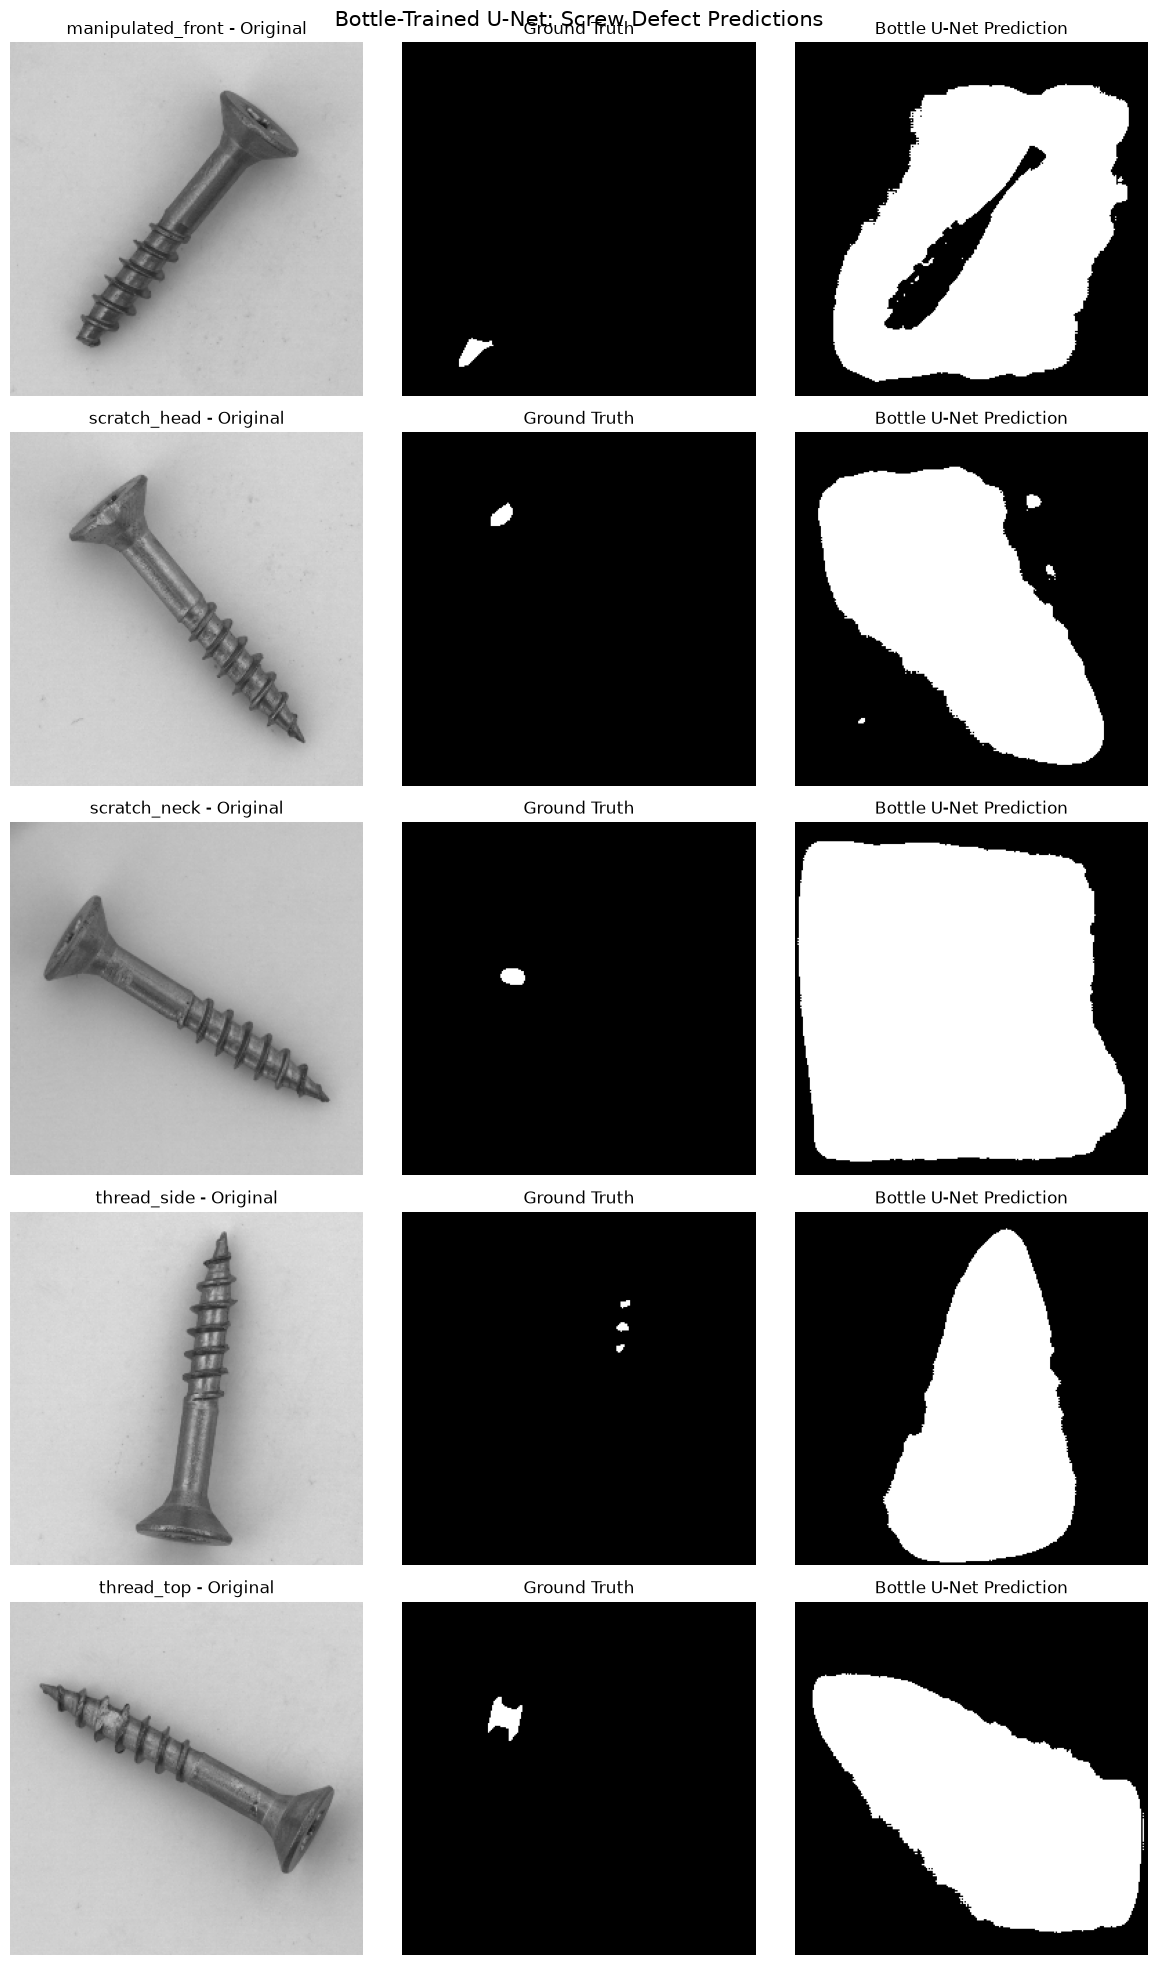


EXPERIMENT 2 COMPLETED
Saved prediction visualization.
Saved category-wise metrics.
Saved experiment report.
Output folder: d:\VisionInspect-AI\outputs\cross_category_screw


In [ ]:

# ==========================================================
# VISIONINSPECT AI
# EXPERIMENT 2: BOTTLE U-NET ON SCREW DATASET
# CROSS-CATEGORY GENERALIZATION EVALUATION
# ==========================================================

import os
import cv2
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. CONFIGURATION
# ----------------------------------------------------------

IMAGE_SIZE = 256
THRESHOLD = 0.5

screw_path = "../datasets/mvtec_ad/screw"
test_path = os.path.join(screw_path, "test")
ground_truth_path = os.path.join(screw_path, "ground_truth")

model_path = "../models/bottle_unet.pth"

output_path = "../outputs/cross_category_screw"
os.makedirs(output_path, exist_ok=True)

print("=" * 60)
print("EXPERIMENT 2: BOTTLE U-NET ON SCREW")
print("=" * 60)

# ----------------------------------------------------------
# 2. LOAD AND PREPROCESS SCREW IMAGES AND MASKS
# ----------------------------------------------------------

X_screw = []
Y_screw = []
screw_labels = []

defect_types = sorted([
    d for d in os.listdir(test_path)
    if os.path.isdir(os.path.join(test_path, d))
    and d != "good"
])

for defect_type in defect_types:

    image_folder = os.path.join(test_path, defect_type)
    mask_folder = os.path.join(ground_truth_path, defect_type)

    image_files = sorted([
        f for f in os.listdir(image_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    for filename in image_files:

        image_path = os.path.join(image_folder, filename)

        stem = os.path.splitext(filename)[0]
        mask_path = os.path.join(mask_folder, stem + "_mask.png")

        if not os.path.exists(mask_path):
            raise FileNotFoundError(
                f"Missing mask for {filename}: {mask_path}"
            )

        image = cv2.imread(image_path)

        if image is None:
            raise ValueError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        image = image.astype(np.float32) / 255.0

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if mask is None:
            raise ValueError(f"Cannot read mask: {mask_path}")

        mask = cv2.resize(
            mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        mask = (mask > 127).astype(np.float32)

        X_screw.append(image)
        Y_screw.append(mask)
        screw_labels.append(defect_type)

X_screw = np.asarray(X_screw, dtype=np.float32)
Y_screw = np.asarray(Y_screw, dtype=np.float32)[..., np.newaxis]
screw_labels = np.asarray(screw_labels)

print("\nPREPROCESSING RESULTS")
print("Images:", X_screw.shape)
print("Masks:", Y_screw.shape)
print("Defect categories:", len(defect_types))
print("Total images:", len(X_screw))

# ----------------------------------------------------------
# 3. LOAD THE SAVED BOTTLE U-NET
# ----------------------------------------------------------

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False
)

model = UNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nBOTTLE U-NET LOADED SUCCESSFULLY")
print("Device:", device)

# ----------------------------------------------------------
# 4. GENERATE PREDICTIONS
# ----------------------------------------------------------

X_tensor = torch.from_numpy(
    X_screw.transpose(0, 3, 1, 2)
).float().to(device)

predicted_masks = []

with torch.no_grad():

    for start in range(0, len(X_tensor), 4):

        batch = X_tensor[start:start + 4]

        logits = model(batch)
        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities > THRESHOLD
        ).float()

        predicted_masks.append(
            predictions.cpu().numpy()
        )

predicted_masks = np.concatenate(predicted_masks, axis=0)

print("\nPREDICTION COMPLETED")
print("Prediction shape:", predicted_masks.shape)

# ----------------------------------------------------------
# 5. CALCULATE OVERALL EVALUATION METRICS
# ----------------------------------------------------------

def calculate_metrics(actual, predicted):

    actual = actual.astype(bool)
    predicted = predicted.astype(bool)

    tp = np.logical_and(actual, predicted).sum()
    fp = np.logical_and(~actual, predicted).sum()
    fn = np.logical_and(actual, ~predicted).sum()

    epsilon = 1e-7

    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    iou = tp / (tp + fp + fn + epsilon)
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)

    return {
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn)
    }

overall_metrics = calculate_metrics(
    Y_screw[..., 0],
    predicted_masks[:, 0]
)

print("\n" + "=" * 60)
print("OVERALL CROSS-CATEGORY RESULTS")
print("=" * 60)

for metric, value in overall_metrics.items():
    print(f"{metric.upper():12s}: {value}")

# ----------------------------------------------------------
# 6. CALCULATE METRICS FOR EACH SCREW DEFECT CATEGORY
# ----------------------------------------------------------

category_results = []

for defect_type in defect_types:

    indices = np.where(screw_labels == defect_type)[0]

    actual = Y_screw[indices, ..., 0]
    predicted = predicted_masks[indices, 0]

    metrics = calculate_metrics(actual, predicted)

    category_results.append({
        "category": defect_type,
        "image_count": len(indices),
        **metrics
    })

category_df = pd.DataFrame(category_results)

print("\nCATEGORY-WISE EVALUATION")
print("=" * 60)
print(category_df.to_string(index=False))

# ----------------------------------------------------------
# 7. VISUALIZE SCREW PREDICTIONS
# ----------------------------------------------------------

fig, axes = plt.subplots(
    len(defect_types), 3,
    figsize=(12, 4 * len(defect_types))
)

for row, defect_type in enumerate(defect_types):

    index = np.where(screw_labels == defect_type)[0][0]

    axes[row, 0].imshow(X_screw[index])
    axes[row, 0].set_title(f"{defect_type} - Original")

    axes[row, 1].imshow(Y_screw[index, ..., 0], cmap="gray")
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(predicted_masks[index, 0], cmap="gray")
    axes[row, 2].set_title("Bottle U-Net Prediction")

    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "Bottle-Trained U-Net: Screw Defect Predictions",
    fontsize=15
)
plt.tight_layout()

plt.savefig(
    os.path.join(output_path, "screw_predictions.png"),
    dpi=150
)

plt.show()

# ----------------------------------------------------------
# 8. SAVE EXPERIMENT RESULTS
# ----------------------------------------------------------

category_df.to_csv(
    os.path.join(output_path, "category_metrics.csv"),
    index=False
)

report = {
    "experiment": "Bottle U-Net on Screw",
    "model": "Bottle-trained U-Net",
    "training_category": "bottle",
    "testing_category": "screw",
    "test_images": len(X_screw),
    "threshold": THRESHOLD,
    "overall_metrics": overall_metrics,
    "category_metrics": category_results,
    "interpretation": (
        "Cross-category generalization evaluation. "
        "No screw images were used to train this model."
    )
}

with open(
    os.path.join(output_path, "experiment_report.json"),
    "w"
) as file:
    json.dump(report, file, indent=4)

print("\n" + "=" * 60)
print("EXPERIMENT 2 COMPLETED")
print("=" * 60)

print("Saved prediction visualization.")
print("Saved category-wise metrics.")
print("Saved experiment report.")
print("Output folder:", os.path.abspath(output_path))


In [ ]:

# =====================================================
# SCREW U-NET - DATA PREPARATION
# =====================================================

import os
import numpy as np
import torch

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create stratified train/validation split
indices = np.arange(len(X_screw))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=screw_labels
)

# Split images and masks
X_train_screw = X_screw[train_indices]
X_val_screw = X_screw[val_indices]

Y_train_screw = Y_screw[train_indices]
Y_val_screw = Y_screw[val_indices]

train_labels_screw = screw_labels[train_indices]
val_labels_screw = screw_labels[val_indices]

# Convert NHWC images to PyTorch NCHW format
X_train_tensor = torch.from_numpy(
    X_train_screw.transpose(0, 3, 1, 2)
).float()

X_val_tensor = torch.from_numpy(
    X_val_screw.transpose(0, 3, 1, 2)
).float()

Y_train_tensor = torch.from_numpy(
    Y_train_screw.transpose(0, 3, 1, 2)
).float()

Y_val_tensor = torch.from_numpy(
    Y_val_screw.transpose(0, 3, 1, 2)
).float()

# Create datasets
train_dataset = TensorDataset(
    X_train_tensor, Y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, Y_val_tensor
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 50)
print("SCREW DATA PREPARATION")
print("=" * 50)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Training tensor:", X_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Device:", device)

print("\nCATEGORY DISTRIBUTION")

for category in sorted(set(screw_labels)):
    print(
        category,
        "| Train:",
        np.sum(train_labels_screw == category),
        "| Validation:",
        np.sum(val_labels_screw == category)
    )

print("\nDATA PREPARATION COMPLETED!")


SCREW DATA PREPARATION
Training images: 95
Validation images: 24
Training batches: 24
Validation batches: 6
Training tensor: torch.Size([95, 3, 256, 256])
Validation tensor: torch.Size([24, 3, 256, 256])
Device: cuda

CATEGORY DISTRIBUTION
manipulated_front | Train: 19 | Validation: 5
scratch_head | Train: 19 | Validation: 5
scratch_neck | Train: 20 | Validation: 5
thread_side | Train: 18 | Validation: 5
thread_top | Train: 19 | Validation: 4

DATA PREPARATION COMPLETED!


Epoch [1/30] Train Loss: 0.7086 | Val Loss: 0.7031 | Val Dice: 0.0000
Epoch [2/30] Train Loss: 0.6537 | Val Loss: 0.6381 | Val Dice: 0.0000
Epoch [3/30] Train Loss: 0.6275 | Val Loss: 0.6054 | Val Dice: 0.0000
Epoch [4/30] Train Loss: 0.6071 | Val Loss: 0.6035 | Val Dice: 0.0000
Epoch [5/30] Train Loss: 0.5900 | Val Loss: 0.5815 | Val Dice: 0.0000
Epoch [6/30] Train Loss: 0.5750 | Val Loss: 0.5721 | Val Dice: 0.0000
Epoch [7/30] Train Loss: 0.5612 | Val Loss: 0.5608 | Val Dice: 0.0794
Epoch [8/30] Train Loss: 0.5462 | Val Loss: 0.6591 | Val Dice: 0.0756
Epoch [9/30] Train Loss: 0.5359 | Val Loss: 1.1252 | Val Dice: 0.0277
Epoch [10/30] Train Loss: 0.5253 | Val Loss: 0.7404 | Val Dice: 0.0400
Epoch [11/30] Train Loss: 0.5144 | Val Loss: 0.5175 | Val Dice: 0.3401
Epoch [12/30] Train Loss: 0.5028 | Val Loss: 0.5408 | Val Dice: 0.3103
Epoch [13/30] Train Loss: 0.4912 | Val Loss: 0.4910 | Val Dice: 0.4504
Epoch [14/30] Train Loss: 0.4801 | Val Loss: 0.6133 | Val Dice: 0.0595
Epoch [15/30] T

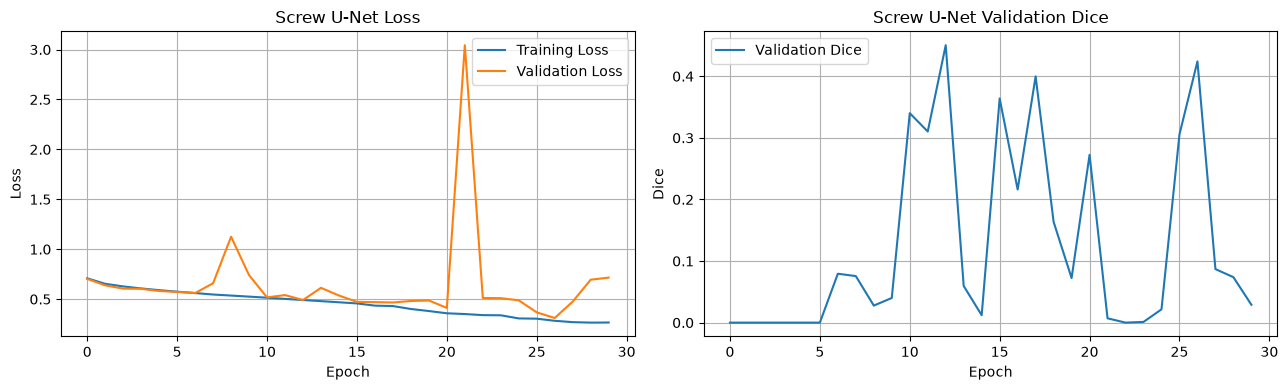

In [ ]:

# =====================================================
# SCREW U-NET - MODEL TRAINING
# =====================================================

import torch.nn as nn
import matplotlib.pyplot as plt

# Use our existing UNet architecture
screw_model = UNet().to(device)

# Loss functions
bce_loss = nn.BCEWithLogitsLoss()

def screw_dice_loss(predictions, targets, smooth=1e-6):
    probabilities = torch.sigmoid(predictions)

    probabilities = probabilities.reshape(-1)
    targets = targets.reshape(-1)

    intersection = (probabilities * targets).sum()

    dice = (
        (2.0 * intersection + smooth) /
        (probabilities.sum() + targets.sum() + smooth)
    )

    return 1 - dice


def screw_combined_loss(predictions, targets):
    return (
        0.5 * bce_loss(predictions, targets)
        + 0.5 * screw_dice_loss(predictions, targets)
    )


optimizer = torch.optim.Adam(
    screw_model.parameters(),
    lr=0.001
)

EPOCHS = 30

train_losses_screw = []
val_losses_screw = []
val_dice_screw = []

best_val_dice = -1.0

# Save experiment outputs
screw_output_dir = "../outputs/screw_unet"
screw_model_dir = "../models"

os.makedirs(screw_output_dir, exist_ok=True)
os.makedirs(screw_model_dir, exist_ok=True)

best_model_path = os.path.join(
    screw_model_dir, "screw_unet_best.pth"
)

# Training loop
for epoch in range(EPOCHS):

    screw_model.train()
    running_train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = screw_model(images)

        loss = screw_combined_loss(predictions, masks)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = (
        running_train_loss / len(train_loader)
    )

    # Validation
    screw_model.eval()

    running_val_loss = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            predictions = screw_model(images)

            loss = screw_combined_loss(
                predictions, masks
            )

            running_val_loss += loss.item()

            predicted_masks = (
                torch.sigmoid(predictions) > 0.5
            ).float()

            total_tp += (
                predicted_masks * masks
            ).sum().item()

            total_fp += (
                predicted_masks * (1 - masks)
            ).sum().item()

            total_fn += (
                (1 - predicted_masks) * masks
            ).sum().item()

    epoch_val_loss = (
        running_val_loss / len(val_loader)
    )

    epoch_val_dice = (
        (2 * total_tp) /
        (2 * total_tp + total_fp + total_fn + 1e-7)
    )

    train_losses_screw.append(epoch_train_loss)
    val_losses_screw.append(epoch_val_loss)
    val_dice_screw.append(epoch_val_dice)

    # Save the best model
    if epoch_val_dice > best_val_dice:

        best_val_dice = epoch_val_dice

        torch.save({
            "model_state_dict": screw_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch + 1,
            "best_val_dice": best_val_dice,
            "category": "screw",
            "image_size": 256,
            "threshold": 0.5
        }, best_model_path)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Dice: {epoch_val_dice:.4f}"
    )

print("\nSCREW U-NET TRAINING COMPLETED!")
print("Best validation Dice:", round(best_val_dice, 4))
print("Best checkpoint:", os.path.abspath(best_model_path))

# Save training history
history = {
    "train_loss": train_losses_screw,
    "val_loss": val_losses_screw,
    "val_dice": val_dice_screw
}

import json

with open(
    os.path.join(screw_output_dir, "training_history.json"),
    "w"
) as file:
    json.dump(history, file, indent=4)

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(train_losses_screw, label="Training Loss")
axes[0].plot(val_losses_screw, label="Validation Loss")
axes[0].set_title("Screw U-Net Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(val_dice_screw, label="Validation Dice")
axes[1].set_title("Screw U-Net Validation Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    os.path.join(screw_output_dir, "training_curves.png"),
    dpi=150
)
plt.show()


SCREW U-NET FINAL EVALUATION
Best training epoch: 13
Validation images: 24
DICE        : 0.4506
IOU         : 0.2908
PRECISION   : 0.3977
RECALL      : 0.5196

CATEGORY-WISE RESULTS
         category  validation_images     dice      iou  precision   recall
manipulated_front                  5 0.522147 0.353315   0.602888 0.460478
     scratch_head                  5 0.242325 0.137867   0.179503 0.372796
     scratch_neck                  5 0.679837 0.514965   0.568237 0.845987
      thread_side                  5 0.025377 0.012851   0.052632 0.016719
       thread_top                  4 0.490262 0.324733   0.368873 0.730731

Validation Loss: 0.491


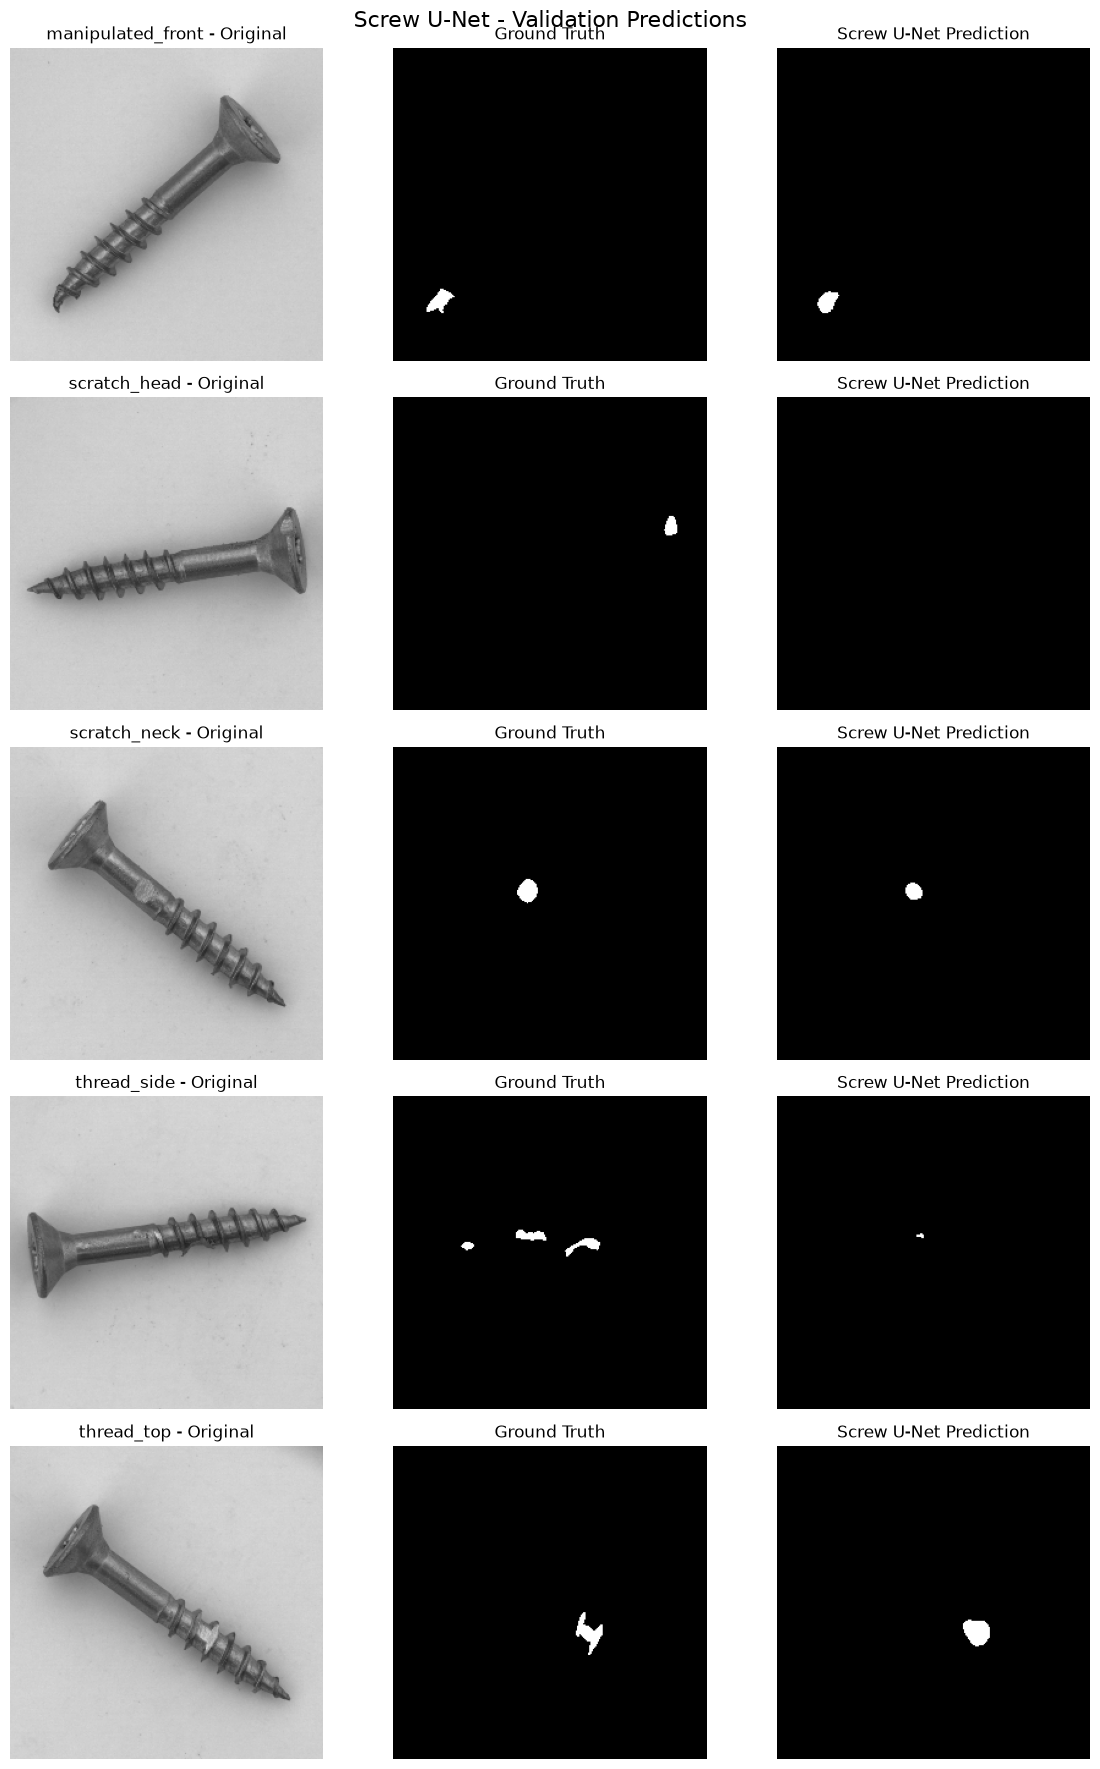


SCREW EXPERIMENT FILE VERIFICATION
Model exists: True
Report exists: True
CSV exists: True
Prediction image exists: True
Training history exists: True

Checkpoint loaded successfully!

SCREW U-NET EXPERIMENT EVALUATION COMPLETED!
Model: d:\VisionInspect-AI\models\screw_unet_best.pth
Results: d:\VisionInspect-AI\outputs\screw_unet


In [ ]:

# =====================================================
# SCREW U-NET - FINAL EVALUATION AND SAVING
# =====================================================

import pandas as pd
import json
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# Load best checkpoint
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

screw_model.load_state_dict(
    checkpoint["model_state_dict"]
)

screw_model.eval()

all_predictions = []

# Generate predictions for validation images
with torch.no_grad():

    for start in range(0, len(X_val_tensor), 4):

        images = X_val_tensor[start:start + 4].to(device)

        predictions = screw_model(images)

        predicted_masks = (
            torch.sigmoid(predictions) > 0.5
        ).float()

        all_predictions.append(
            predicted_masks.cpu().numpy()
        )

all_predictions = np.concatenate(
    all_predictions, axis=0
)

actual_masks = Y_val_screw[..., 0]
predicted_masks = all_predictions[:, 0]

# Metric calculation function
def evaluate_segmentation(actual, predicted):

    actual = actual.astype(bool)
    predicted = predicted.astype(bool)

    tp = np.logical_and(actual, predicted).sum()
    fp = np.logical_and(~actual, predicted).sum()
    fn = np.logical_and(actual, ~predicted).sum()

    epsilon = 1e-7

    return {
        "dice": float(
            2 * tp / (2 * tp + fp + fn + epsilon)
        ),
        "iou": float(
            tp / (tp + fp + fn + epsilon)
        ),
        "precision": float(
            tp / (tp + fp + epsilon)
        ),
        "recall": float(
            tp / (tp + fn + epsilon)
        )
    }

# Overall metrics
overall = evaluate_segmentation(
    actual_masks, predicted_masks
)

# Category-wise metrics
category_results = []

for category in sorted(set(val_labels_screw)):

    indices = np.where(
        val_labels_screw == category
    )[0]

    metrics = evaluate_segmentation(
        actual_masks[indices],
        predicted_masks[indices]
    )

    category_results.append({
        "category": category,
        "validation_images": len(indices),
        **metrics
    })

category_df = pd.DataFrame(category_results)

print("=" * 55)
print("SCREW U-NET FINAL EVALUATION")
print("=" * 55)

print("Best training epoch:", checkpoint["epoch"])
print("Validation images:", len(X_val_tensor))

for metric, value in overall.items():
    print(f"{metric.upper():12s}: {value:.4f}")

print("\nCATEGORY-WISE RESULTS")
print(category_df.to_string(index=False))

# Calculate validation loss for the best checkpoint
screw_model.eval()
validation_loss_total = 0.0

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)

        predictions = screw_model(images)

        validation_loss_total += (
            screw_combined_loss(predictions, masks).item()
        )

final_validation_loss = (
    validation_loss_total / len(val_loader)
)

print("\nValidation Loss:", round(final_validation_loss, 4))

# -----------------------------------------------------
# VISUALIZE VALIDATION PREDICTIONS
# -----------------------------------------------------

fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for row, category in enumerate(sorted(set(val_labels_screw))):

    indices = np.where(
        val_labels_screw == category
    )[0]

    index = indices[0]

    axes[row, 0].imshow(X_val_screw[index])
    axes[row, 0].set_title(f"{category} - Original")

    axes[row, 1].imshow(
        actual_masks[index], cmap="gray"
    )
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(
        predicted_masks[index], cmap="gray"
    )
    axes[row, 2].set_title("Screw U-Net Prediction")

    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "Screw U-Net - Validation Predictions",
    fontsize=16
)

plt.tight_layout()

prediction_path = os.path.join(
    screw_output_dir, "screw_validation_predictions.png"
)

plt.savefig(prediction_path, dpi=150)
plt.show()

# -----------------------------------------------------
# SAVE EVALUATION REPORT
# -----------------------------------------------------

report = {
    "experiment": "Screw-only U-Net",
    "model": "U-Net",
    "training_images": len(X_train_tensor),
    "validation_images": len(X_val_tensor),
    "epochs_completed": EPOCHS,
    "best_epoch": checkpoint["epoch"],
    "best_epoch_validation_dice": float(
        checkpoint["best_val_dice"]
    ),
    "final_validation_loss": float(final_validation_loss),
    "overall_metrics": overall,
    "category_metrics": category_results,
    "dataset_protocol": (
        "Exploratory custom stratified split of labelled "
        "MVTec AD test images; not official benchmark evaluation."
    )
}

report_path = os.path.join(
    screw_output_dir, "screw_evaluation.json"
)

with open(report_path, "w") as file:
    json.dump(report, file, indent=4)

category_df.to_csv(
    os.path.join(screw_output_dir, "category_metrics.csv"),
    index=False
)

# -----------------------------------------------------
# VERIFY SAVED FILES AND CHECKPOINT
# -----------------------------------------------------

print("\n" + "=" * 55)
print("SCREW EXPERIMENT FILE VERIFICATION")
print("=" * 55)

print("Model exists:", os.path.exists(best_model_path))
print("Report exists:", os.path.exists(report_path))
print("CSV exists:", os.path.exists(
    os.path.join(screw_output_dir, "category_metrics.csv")
))
print("Prediction image exists:", os.path.exists(prediction_path))
print("Training history exists:", os.path.exists(
    os.path.join(screw_output_dir, "training_history.json")
))

# Verify checkpoint can be loaded
verified_checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

verification_model = UNet().to(device)

verification_model.load_state_dict(
    verified_checkpoint["model_state_dict"]
)

print("\nCheckpoint loaded successfully!")

print("\nSCREW U-NET EXPERIMENT EVALUATION COMPLETED!")
print("Model:", os.path.abspath(best_model_path))
print("Results:", os.path.abspath(screw_output_dir))


In [5]:

# ==========================================================
# VISIONINSPECT AI
# EXPERIMENT 3B: AUGMENTED SCREW U-NET
# ==========================================================

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

# ----------------------------------------------------------
# 1. REPRODUCIBILITY
# ----------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ----------------------------------------------------------
# 2. AUGMENTED DATASET
# ----------------------------------------------------------

class ScrewAugmentedDataset(Dataset):

    def __init__(self, images, masks):
        self.images = torch.from_numpy(
            images.transpose(0, 3, 1, 2)
        ).float()

        self.masks = torch.from_numpy(
            masks.transpose(0, 3, 1, 2)
        ).float()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image = self.images[index].clone()
        mask = self.masks[index].clone()

        # Random horizontal flip
        if random.random() < 0.5:
            image = torch.flip(image, dims=[2])
            mask = torch.flip(mask, dims=[2])

        # Random vertical flip
        if random.random() < 0.5:
            image = torch.flip(image, dims=[1])
            mask = torch.flip(mask, dims=[1])

        # Random 90-degree rotation
        k = random.randint(0, 3)

        image = torch.rot90(image, k, dims=[1, 2])
        mask = torch.rot90(mask, k, dims=[1, 2])

        # Mild brightness and contrast variation
        contrast = random.uniform(0.85, 1.15)
        brightness = random.uniform(0.90, 1.10)

        image = (image - 0.5) * contrast + 0.5
        image = image * brightness
        image = torch.clamp(image, 0.0, 1.0)

        return image, mask


# Augmentation only for training data
augmented_train_dataset = ScrewAugmentedDataset(
    X_train_screw,
    Y_train_screw
)

# Validation remains unchanged
validation_dataset = TensorDataset(
    X_val_tensor,
    Y_val_tensor
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=4,
    shuffle=True
)

augmented_val_loader = DataLoader(
    validation_dataset,
    batch_size=4,
    shuffle=False
)

print("AUGMENTED DATASET CREATED")
print("Training images:", len(augmented_train_dataset))
print("Validation images:", len(validation_dataset))
print("Training batches:", len(augmented_train_loader))
print("Validation batches:", len(augmented_val_loader))

# ----------------------------------------------------------
# 3. FRESH U-NET MODEL
# ----------------------------------------------------------

aug_model = UNet().to(device)

# BCE + Dice Loss
bce_aug = nn.BCEWithLogitsLoss()


def dice_loss_aug(predictions, targets, smooth=1e-6):

    probabilities = torch.sigmoid(predictions)

    probabilities = probabilities.reshape(-1)
    targets = targets.reshape(-1)

    intersection = (probabilities * targets).sum()

    dice = (
        (2 * intersection + smooth) /
        (probabilities.sum() + targets.sum() + smooth)
    )

    return 1 - dice


def combined_loss_aug(predictions, targets):

    return (
        0.5 * bce_aug(predictions, targets)
        + 0.5 * dice_loss_aug(predictions, targets)
    )


optimizer_aug = torch.optim.Adam(
    aug_model.parameters(),
    lr=0.001
)

scheduler_aug = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_aug,
    mode="min",
    factor=0.5,
    patience=5
)

MAX_EPOCHS = 60
EARLY_STOPPING_PATIENCE = 12

best_dice_aug = -1.0
best_loss_aug = float("inf")
epochs_without_improvement = 0

train_history_aug = []
val_history_aug = []
dice_history_aug = []

# ----------------------------------------------------------
# 4. OUTPUT DIRECTORIES
# ----------------------------------------------------------

aug_output_dir = "../outputs/screw_unet_augmented"
aug_model_path = "../models/screw_unet_augmented_best.pth"

os.makedirs(aug_output_dir, exist_ok=True)
os.makedirs("../models", exist_ok=True)

# ----------------------------------------------------------
# 5. TRAINING
# ----------------------------------------------------------

print("\nSTARTING AUGMENTED SCREW U-NET TRAINING")
print("=" * 60)

for epoch in range(MAX_EPOCHS):

    aug_model.train()
    train_loss_total = 0.0

    for images, masks in augmented_train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer_aug.zero_grad()

        predictions = aug_model(images)

        loss = combined_loss_aug(predictions, masks)

        loss.backward()
        optimizer_aug.step()

        train_loss_total += loss.item()

    epoch_train_loss = (
        train_loss_total / len(augmented_train_loader)
    )

    # ------------------------------------------------------
    # VALIDATION
    # ------------------------------------------------------

    aug_model.eval()

    val_loss_total = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0

    with torch.no_grad():

        for images, masks in augmented_val_loader:

            images = images.to(device)
            masks = masks.to(device)

            predictions = aug_model(images)

            loss = combined_loss_aug(predictions, masks)
            val_loss_total += loss.item()

            predicted_masks = (
                torch.sigmoid(predictions) > 0.5
            ).float()

            total_tp += (
                predicted_masks * masks
            ).sum().item()

            total_fp += (
                predicted_masks * (1 - masks)
            ).sum().item()

            total_fn += (
                (1 - predicted_masks) * masks
            ).sum().item()

    epoch_val_loss = (
        val_loss_total / len(augmented_val_loader)
    )

    epoch_val_dice = (
        (2 * total_tp) /
        (2 * total_tp + total_fp + total_fn + 1e-7)
    )

    scheduler_aug.step(epoch_val_loss)

    train_history_aug.append(epoch_train_loss)
    val_history_aug.append(epoch_val_loss)
    dice_history_aug.append(epoch_val_dice)

    current_lr = optimizer_aug.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1}/{MAX_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Dice: {epoch_val_dice:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # ------------------------------------------------------
    # SAVE BEST CHECKPOINT
    # ------------------------------------------------------

    if epoch_val_dice > best_dice_aug:

        best_dice_aug = epoch_val_dice
        best_loss_aug = epoch_val_loss

        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": aug_model.state_dict(),
            "optimizer_state_dict": optimizer_aug.state_dict(),
            "epoch": epoch + 1,
            "best_val_dice": float(best_dice_aug),
            "best_val_loss": float(best_loss_aug),
            "category": "screw",
            "augmentation": True,
            "image_size": 256,
            "threshold": 0.5
        }, aug_model_path)

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEARLY STOPPING TRIGGERED")
        break


# ----------------------------------------------------------
# 6. SAVE TRAINING HISTORY
# ----------------------------------------------------------

history_aug = {
    "train_loss": train_history_aug,
    "val_loss": val_history_aug,
    "val_dice": dice_history_aug
}

with open(
    os.path.join(aug_output_dir, "training_history.json"),
    "w"
) as file:
    json.dump(history_aug, file, indent=4)


# ----------------------------------------------------------
# 7. PLOT TRAINING CURVES
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(train_history_aug, label="Training Loss")
axes[0].plot(val_history_aug, label="Validation Loss")
axes[0].set_title("Augmented Screw U-Net Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(dice_history_aug, label="Validation Dice")
axes[1].set_title("Augmented Screw U-Net Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(aug_output_dir, "training_curves.png"),
    dpi=150
)

plt.show()


# ----------------------------------------------------------
# 8. FINAL TRAINING SUMMARY
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("AUGMENTED SCREW U-NET TRAINING COMPLETED")
print("=" * 60)

print("Epochs completed:", len(train_history_aug))
print("Best validation Dice:", round(best_dice_aug, 4))
print("Best validation loss:", round(best_loss_aug, 4))
print("Checkpoint exists:", os.path.exists(aug_model_path))
print("Checkpoint:", os.path.abspath(aug_model_path))

print("\nTraining history saved.")
print("Training curves saved.")


NameError: name 'X_train_screw' is not defined

In [4]:
# CHECK BEST AUGMENTED MODEL PERFORMANCE

best_epoch_index = np.argmax(dice_history_aug)

print("BEST AUGMENTED DICE:",
      round(dice_history_aug[best_epoch_index], 4))

print("BEST EPOCH:", best_epoch_index + 1)

print("ORIGINAL BEST DICE: 0.4506")

checkpoint = torch.load(
    aug_model_path,
    map_location=device,
    weights_only=False
)

print("SAVED CHECKPOINT DICE:",
      checkpoint["best_val_dice"])

print("CHECKPOINT EPOCH:",
      checkpoint["epoch"])

print("CHECKPOINT EXISTS:",
      os.path.exists(aug_model_path))

NameError: name 'dice_history_aug' is not defined

Best checkpoint loaded!
Best epoch: 54
Best training validation Dice: 0.48537378114317037

AUGMENTED SCREW U-NET RESULTS
Validation images: 24
DICE        : 0.4854
IOU         : 0.3205
PRECISION   : 0.5589
RECALL      : 0.4290

CATEGORY-WISE RESULTS
         category  validation_images     dice      iou  precision   recall
manipulated_front                  5 0.000000 0.000000   0.000000 0.000000
     scratch_head                  5 0.452700 0.292574   0.344510 0.659950
     scratch_neck                  5 0.774536 0.632035   0.715248 0.844541
      thread_side                  5 0.054795 0.028169   0.430769 0.029258
       thread_top                  4 0.587239 0.415667   0.673575 0.520521

Validation Loss: 0.2804


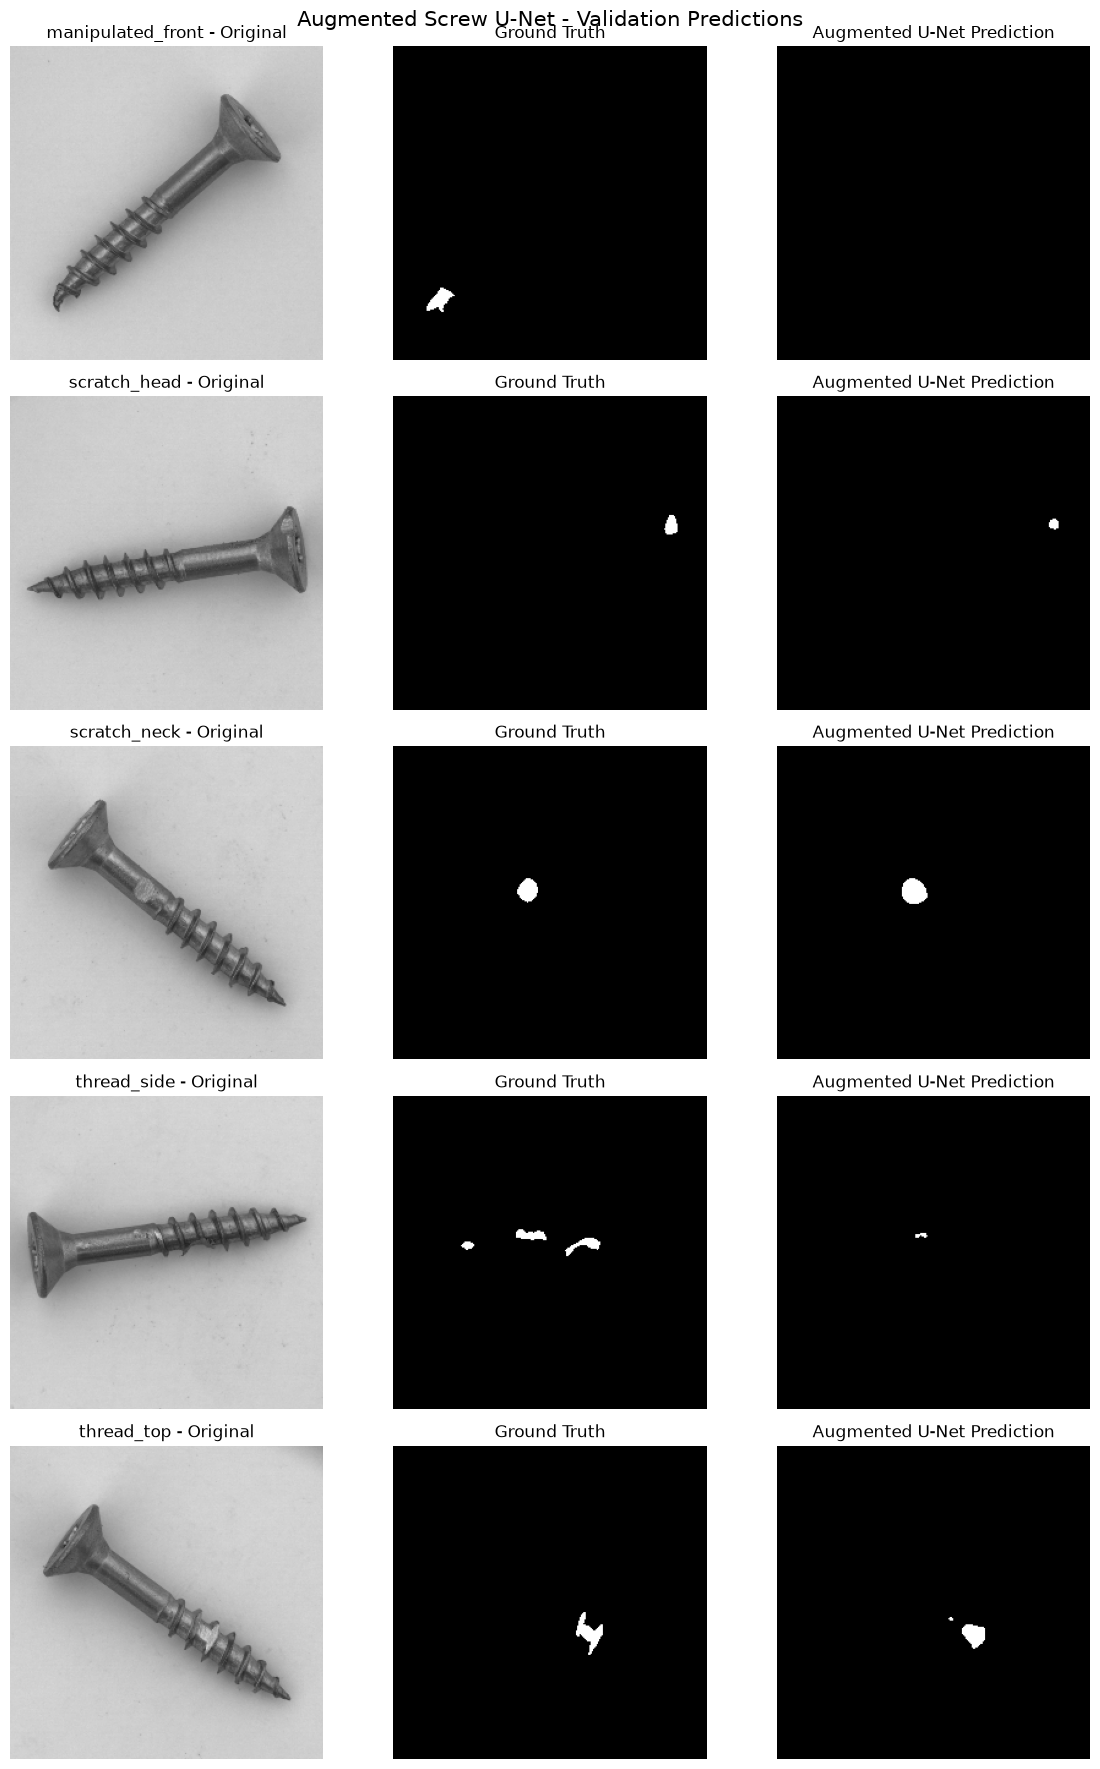


AUGMENTED MODEL FILE VERIFICATION
Checkpoint: True
Evaluation report: True
Category CSV: True
Prediction image: True
Training history: True

Checkpoint loaded successfully!

AUGMENTED SCREW EVALUATION COMPLETED!
Report: d:\VisionInspect-AI\outputs\screw_unet_augmented\augmented_evaluation.json


In [ ]:

# ==========================================================
# EXPERIMENT 3B: AUGMENTED SCREW U-NET FINAL EVALUATION
# ==========================================================

import os
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. LOAD BEST AUGMENTED CHECKPOINT
# ----------------------------------------------------------

aug_model = UNet().to(device)

checkpoint = torch.load(
    aug_model_path,
    map_location=device,
    weights_only=False
)

aug_model.load_state_dict(checkpoint["model_state_dict"])
aug_model.eval()

print("Best checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best training validation Dice:", checkpoint["best_val_dice"])

# ----------------------------------------------------------
# 2. GENERATE VALIDATION PREDICTIONS
# ----------------------------------------------------------

all_predictions_aug = []

with torch.no_grad():

    for start in range(0, len(X_val_tensor), 4):

        images = X_val_tensor[start:start + 4].to(device)

        logits = aug_model(images)

        predictions = (
            torch.sigmoid(logits) > 0.5
        ).float()

        all_predictions_aug.append(
            predictions.cpu().numpy()
        )

all_predictions_aug = np.concatenate(
    all_predictions_aug, axis=0
)

actual_masks_aug = Y_val_screw[..., 0]
predicted_masks_aug = all_predictions_aug[:, 0]

# ----------------------------------------------------------
# 3. METRIC CALCULATION
# ----------------------------------------------------------

def calculate_aug_metrics(actual, predicted):

    actual = actual.astype(bool)
    predicted = predicted.astype(bool)

    tp = np.logical_and(actual, predicted).sum()
    fp = np.logical_and(~actual, predicted).sum()
    fn = np.logical_and(actual, ~predicted).sum()

    eps = 1e-7

    return {
        "dice": float(
            2 * tp / (2 * tp + fp + fn + eps)
        ),
        "iou": float(
            tp / (tp + fp + fn + eps)
        ),
        "precision": float(
            tp / (tp + fp + eps)
        ),
        "recall": float(
            tp / (tp + fn + eps)
        )
    }

# Overall metrics
overall_aug = calculate_aug_metrics(
    actual_masks_aug,
    predicted_masks_aug
)

print("\n" + "=" * 55)
print("AUGMENTED SCREW U-NET RESULTS")
print("=" * 55)

print("Validation images:", len(X_val_tensor))

for metric, value in overall_aug.items():
    print(f"{metric.upper():12s}: {value:.4f}")

# ----------------------------------------------------------
# 4. CATEGORY-WISE METRICS
# ----------------------------------------------------------

category_results_aug = []

for category in sorted(set(val_labels_screw)):

    indices = np.where(
        val_labels_screw == category
    )[0]

    metrics = calculate_aug_metrics(
        actual_masks_aug[indices],
        predicted_masks_aug[indices]
    )

    category_results_aug.append({
        "category": category,
        "validation_images": len(indices),
        **metrics
    })

category_df_aug = pd.DataFrame(category_results_aug)

print("\nCATEGORY-WISE RESULTS")
print(category_df_aug.to_string(index=False))

# ----------------------------------------------------------
# 5. CALCULATE VALIDATION LOSS
# ----------------------------------------------------------

validation_loss_total = 0.0

with torch.no_grad():

    for images, masks in augmented_val_loader:

        images = images.to(device)
        masks = masks.to(device)

        predictions = aug_model(images)

        validation_loss_total += (
            combined_loss_aug(predictions, masks).item()
        )

final_aug_val_loss = (
    validation_loss_total / len(augmented_val_loader)
)

print("\nValidation Loss:", round(final_aug_val_loss, 4))

# ----------------------------------------------------------
# 6. VISUALIZE PREDICTIONS
# ----------------------------------------------------------

fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for row, category in enumerate(sorted(set(val_labels_screw))):

    indices = np.where(
        val_labels_screw == category
    )[0]

    index = indices[0]

    axes[row, 0].imshow(X_val_screw[index])
    axes[row, 0].set_title(f"{category} - Original")

    axes[row, 1].imshow(
        actual_masks_aug[index], cmap="gray"
    )
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(
        predicted_masks_aug[index], cmap="gray"
    )
    axes[row, 2].set_title("Augmented U-Net Prediction")

    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "Augmented Screw U-Net - Validation Predictions",
    fontsize=15
)

plt.tight_layout()

prediction_path_aug = os.path.join(
    aug_output_dir, "augmented_validation_predictions.png"
)

plt.savefig(prediction_path_aug, dpi=150)
plt.show()

# ----------------------------------------------------------
# 7. SAVE EVALUATION REPORT
# ----------------------------------------------------------

report_aug = {
    "experiment": "Augmented Screw U-Net",
    "model": "U-Net",
    "augmentation": True,
    "training_images": len(X_train_tensor),
    "validation_images": len(X_val_tensor),
    "best_epoch": checkpoint["epoch"],
    "best_training_validation_dice": float(
        checkpoint["best_val_dice"]
    ),
    "final_validation_loss": float(final_aug_val_loss),
    "overall_metrics": overall_aug,
    "category_metrics": category_results_aug,
    "dataset_protocol": (
        "Exploratory custom split of labelled MVTec AD test images; "
        "not official benchmark evaluation."
    )
}

report_path_aug = os.path.join(
    aug_output_dir, "augmented_evaluation.json"
)

with open(report_path_aug, "w") as file:
    json.dump(report_aug, file, indent=4)

csv_path_aug = os.path.join(
    aug_output_dir, "category_metrics.csv"
)

category_df_aug.to_csv(csv_path_aug, index=False)

# ----------------------------------------------------------
# 8. VERIFY SAVED FILES
# ----------------------------------------------------------

print("\n" + "=" * 55)
print("AUGMENTED MODEL FILE VERIFICATION")
print("=" * 55)

print("Checkpoint:", os.path.exists(aug_model_path))
print("Evaluation report:", os.path.exists(report_path_aug))
print("Category CSV:", os.path.exists(csv_path_aug))
print("Prediction image:", os.path.exists(prediction_path_aug))
print(
    "Training history:",
    os.path.exists(
        os.path.join(aug_output_dir, "training_history.json")
    )
)

# Verify checkpoint can be loaded
verified_model = UNet().to(device)

verified_checkpoint = torch.load(
    aug_model_path,
    map_location=device,
    weights_only=False
)

verified_model.load_state_dict(
    verified_checkpoint["model_state_dict"]
)

print("\nCheckpoint loaded successfully!")

print("\nAUGMENTED SCREW EVALUATION COMPLETED!")
print("Report:", os.path.abspath(report_path_aug))


In [ ]:

import numpy as np

# --------------------------------------------------
# 1. Check required datasets
# --------------------------------------------------

required_variables = [
    "X",
    "Y",
    "X_screw",
    "Y_screw",
    "screw_labels"
]

for name in required_variables:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Please run the relevant data preparation cells."
        )

# --------------------------------------------------
# 2. Display dataset dimensions
# --------------------------------------------------

print("=" * 55)
print("EXISTING DATASET VERIFICATION")
print("=" * 55)

print("\nBOTTLE DATASET")
print("Images:", X.shape)
print("Masks:", Y.shape)

print("\nSCREW DATASET")
print("Images:", X_screw.shape)
print("Masks:", Y_screw.shape)
print("Screw labels:", screw_labels.shape)

# --------------------------------------------------
# 3. Validate image-mask correspondence
# --------------------------------------------------

assert len(X) == len(Y), "Bottle image-mask count mismatch!"
assert len(X_screw) == len(Y_screw), "Screw image-mask count mismatch!"
assert len(X_screw) == len(screw_labels), "Screw label count mismatch!"

assert X.shape[1:] == X_screw.shape[1:], \
    "Bottle and Screw image dimensions differ."

assert Y.shape[1:] == Y_screw.shape[1:], \
    "Bottle and Screw mask dimensions differ."

print("\nIMAGE AND MASK DIMENSIONS MATCH.")

# --------------------------------------------------
# 4. Dataset statistics
# --------------------------------------------------

print("\nTOTAL DATASET SIZE")
print("Bottle images:", len(X))
print("Screw images:", len(X_screw))
print("Combined images:", len(X) + len(X_screw))

print("\nBOTTLE PIXEL RANGE:", X.min(), "to", X.max())
print("SCREW PIXEL RANGE:", X_screw.min(), "to", X_screw.max())

print("\nBOTTLE MASK VALUES:", np.unique(Y))
print("SCREW MASK VALUES:", np.unique(Y_screw))

print("\nSCREW DEFECT DISTRIBUTION:")
unique_labels, counts = np.unique(
    screw_labels,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(f"{label}: {count} images")

# --------------------------------------------------
# 5. Find existing Bottle label variables
# --------------------------------------------------

print("\nPOSSIBLE BOTTLE LABEL VARIABLES:")

for name, value in globals().copy().items():
    if (
        "label" in name.lower()
        or "bottle" in name.lower()
        or "defect" in name.lower()
    ):
        if isinstance(value, (np.ndarray, list)):
            print(
                name,
                "| shape/length:",
                getattr(value, "shape", len(value))
            )

print("\nDATASET VERIFICATION COMPLETED.")


EXISTING DATASET VERIFICATION

BOTTLE DATASET
Images: (63, 256, 256, 3)
Masks: (63, 256, 256, 1)

SCREW DATASET
Images: (119, 256, 256, 3)
Masks: (119, 256, 256, 1)
Screw labels: (119,)

IMAGE AND MASK DIMENSIONS MATCH.

TOTAL DATASET SIZE
Bottle images: 63
Screw images: 119
Combined images: 182

BOTTLE PIXEL RANGE: 0.09803922 to 1.0
SCREW PIXEL RANGE: 0.078431375 to 0.95686275

BOTTLE MASK VALUES: [0. 1.]
SCREW MASK VALUES: [0. 1.]

SCREW DEFECT DISTRIBUTION:
manipulated_front: 24 images
scratch_head: 24 images
scratch_neck: 25 images
thread_side: 23 images
thread_top: 23 images

POSSIBLE BOTTLE LABEL VARIABLES:
defect_types | shape/length: 5
labels | shape/length: (63,)
screw_defect_types | shape/length: 5
screw_labels | shape/length: (119,)
train_labels_screw | shape/length: (95,)
val_labels_screw | shape/length: (24,)
unique_labels | shape/length: (5,)

DATASET VERIFICATION COMPLETED.


In [ ]:

import numpy as np
import pandas as pd
import torch
import hashlib

# --------------------------------------------------
# 1. Convert Bottle tensors from NCHW to NHWC
# --------------------------------------------------

def tensor_to_nhwc(tensor):
    return (
        tensor.detach()
        .cpu()
        .permute(0, 2, 3, 1)
        .numpy()
        .astype(np.float32)
    )

X_train_bottle = tensor_to_nhwc(X_train)
X_val_bottle = tensor_to_nhwc(X_val)

Y_train_bottle = tensor_to_nhwc(Y_train)
Y_val_bottle = tensor_to_nhwc(Y_val)

# --------------------------------------------------
# 2. Verify normalized formats
# --------------------------------------------------

print("BOTTLE FORMATS AFTER CONVERSION")
print("Training images:", X_train_bottle.shape)
print("Training masks:", Y_train_bottle.shape)
print("Validation images:", X_val_bottle.shape)
print("Validation masks:", Y_val_bottle.shape)

# --------------------------------------------------
# 3. Validate dimensions
# --------------------------------------------------

assert X_train_bottle.shape[1:] == X_train_screw.shape[1:]
assert X_val_bottle.shape[1:] == X_val_screw.shape[1:]

assert Y_train_bottle.shape[1:] == Y_train_screw.shape[1:]
assert Y_val_bottle.shape[1:] == Y_val_screw.shape[1:]

# --------------------------------------------------
# 4. Combine training datasets
# --------------------------------------------------

X_train_combined = np.concatenate(
    [X_train_bottle, X_train_screw],
    axis=0
)

Y_train_combined = np.concatenate(
    [Y_train_bottle, Y_train_screw],
    axis=0
)

train_product_labels = np.array(
    ["bottle"] * len(X_train_bottle)
    + ["screw"] * len(X_train_screw)
)

# --------------------------------------------------
# 5. Combine validation datasets
# --------------------------------------------------

X_val_combined = np.concatenate(
    [X_val_bottle, X_val_screw],
    axis=0
)

Y_val_combined = np.concatenate(
    [Y_val_bottle, Y_val_screw],
    axis=0
)

val_product_labels = np.array(
    ["bottle"] * len(X_val_bottle)
    + ["screw"] * len(X_val_screw)
)

# --------------------------------------------------
# 6. Check for duplicate images across splits
# --------------------------------------------------

def calculate_image_hashes(images):
    return {
        hashlib.sha256(
            np.ascontiguousarray(image).tobytes()
        ).hexdigest()
        for image in images
    }

train_hashes = calculate_image_hashes(X_train_combined)
val_hashes = calculate_image_hashes(X_val_combined)

overlap = train_hashes.intersection(val_hashes)

assert len(overlap) == 0, "Duplicate images found across splits!"

# --------------------------------------------------
# 7. Verify masks and labels
# --------------------------------------------------

assert len(X_train_combined) == len(Y_train_combined)
assert len(X_val_combined) == len(Y_val_combined)

assert len(X_train_combined) == len(train_product_labels)
assert len(X_val_combined) == len(val_product_labels)

assert np.array_equal(
    np.unique(Y_train_combined),
    np.array([0.0, 1.0])
)

# --------------------------------------------------
# 8. Final dataset summary
# --------------------------------------------------

print("\n" + "=" * 55)
print("COMBINED DATASET PREPARATION COMPLETE")
print("=" * 55)

print("\nTRAINING")
print("Images:", X_train_combined.shape)
print("Masks:", Y_train_combined.shape)

print("\nVALIDATION")
print("Images:", X_val_combined.shape)
print("Masks:", Y_val_combined.shape)

summary = pd.DataFrame({
    "Product": ["Bottle", "Screw", "Total"],
    "Training": [
        len(X_train_bottle),
        len(X_train_screw),
        len(X_train_combined)
    ],
    "Validation": [
        len(X_val_bottle),
        len(X_val_screw),
        len(X_val_combined)
    ]
})

display(summary)

print("Duplicate images across splits:", len(overlap))
print("Image range:", X_train_combined.min(), "to", X_train_combined.max())
print("Mask values:", np.unique(Y_train_combined))

print("\nCombined dataset is ready!")


BOTTLE FORMATS AFTER CONVERSION
Training images: (50, 256, 256, 3)
Training masks: (50, 256, 256, 1)
Validation images: (13, 256, 256, 3)
Validation masks: (13, 256, 256, 1)

COMBINED DATASET PREPARATION COMPLETE

TRAINING
Images: (145, 256, 256, 3)
Masks: (145, 256, 256, 1)

VALIDATION
Images: (37, 256, 256, 3)
Masks: (37, 256, 256, 1)


,Product,Training,Validation
0,Bottle,50,13
1,Screw,95,24
2,Total,145,37


Duplicate images across splits: 0
Image range: 0.078431375 to 1.0
Mask values: [0. 1.]

Combined dataset is ready!


Training device: cuda

DATALOADER SUMMARY
Training batches: 37
Validation batches: 10
Batch size: 4

SAMPLE BATCH
Images: torch.Size([4, 3, 256, 256])
Masks: torch.Size([4, 1, 256, 256])

Trainable parameters: 1944049
Epoch 01/60 | Train Loss: 0.7447 | Val Loss: 0.6898 | Bottle Dice: 0.0014 | Screw Dice: 0.0020 | Macro Dice: 0.0017
  Best combined model checkpoint saved.
Epoch 02/60 | Train Loss: 0.6724 | Val Loss: 0.6581 | Bottle Dice: 0.0002 | Screw Dice: 0.0000 | Macro Dice: 0.0001
Epoch 03/60 | Train Loss: 0.6323 | Val Loss: 0.6613 | Bottle Dice: 0.1659 | Screw Dice: 0.0794 | Macro Dice: 0.1227
  Best combined model checkpoint saved.
Epoch 04/60 | Train Loss: 0.6014 | Val Loss: 0.6149 | Bottle Dice: 0.2346 | Screw Dice: 0.0273 | Macro Dice: 0.1309
  Best combined model checkpoint saved.
Epoch 05/60 | Train Loss: 0.5781 | Val Loss: 0.6207 | Bottle Dice: 0.2568 | Screw Dice: 0.0651 | Macro Dice: 0.1610
  Best combined model checkpoint saved.
Epoch 06/60 | Train Loss: 0.5567 | Val Los

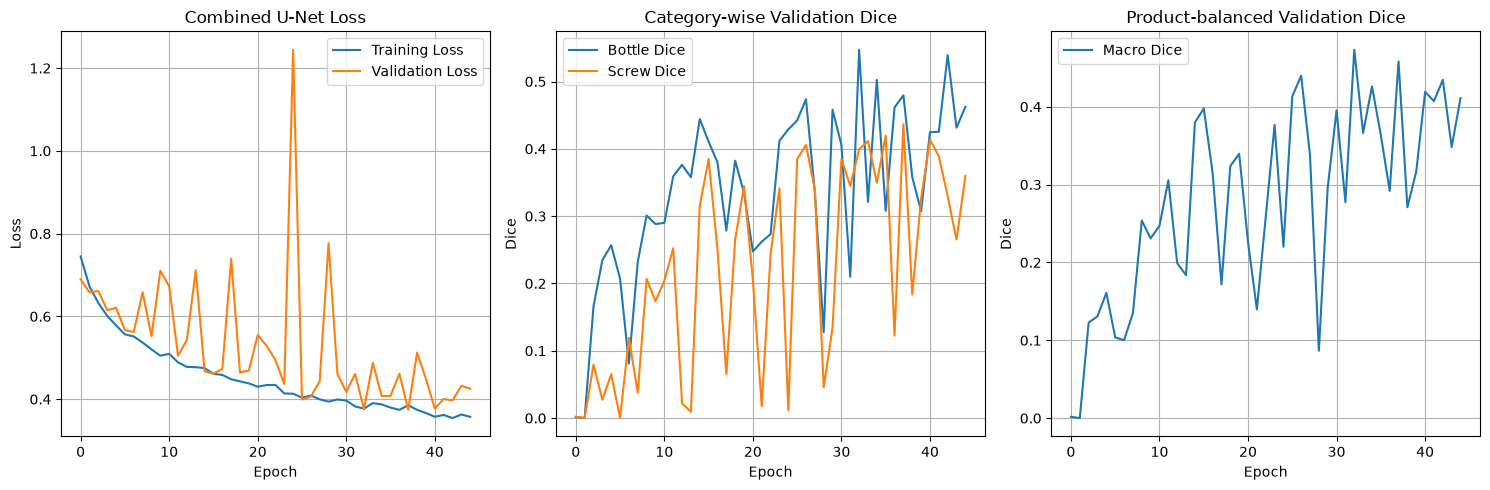


COMBINED BOTTLE + SCREW U-NET SUMMARY
Best epoch: 33
Best macro Dice: 0.4731
Checkpoint saved: True
Training history saved: True
Training curves saved: True


In [ ]:

import os
import json
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from pathlib import Path

# --------------------------------------------------
# 1. Reproducibility and device
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)

# --------------------------------------------------
# 2. Combined augmentation dataset
# --------------------------------------------------

class CombinedAugmentedDataset(Dataset):

    def __init__(self, images, masks, augment=False):
        self.images = images
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image = torch.from_numpy(
            self.images[index].copy()
        ).permute(2, 0, 1)

        mask = torch.from_numpy(
            self.masks[index].copy()
        ).permute(2, 0, 1)

        if self.augment:

            # Horizontal flip
            if random.random() < 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])

            # Vertical flip
            if random.random() < 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[1])

            # Rotation by multiples of 90 degrees
            k = random.randint(0, 3)

            image = torch.rot90(image, k, dims=[1, 2])
            mask = torch.rot90(mask, k, dims=[1, 2])

            # Mild brightness and contrast adjustment
            brightness = random.uniform(0.90, 1.10)
            contrast = random.uniform(0.85, 1.15)

            mean = image.mean(dim=(1, 2), keepdim=True)

            image = (image - mean) * contrast + mean
            image = image * brightness
            image = torch.clamp(image, 0.0, 1.0)

        return image.float(), mask.float()


# --------------------------------------------------
# 3. Create training and validation loaders
# --------------------------------------------------

train_dataset_combined = CombinedAugmentedDataset(
    X_train_combined,
    Y_train_combined,
    augment=True
)

val_dataset_combined = CombinedAugmentedDataset(
    X_val_combined,
    Y_val_combined,
    augment=False
)

BATCH_SIZE = 4

train_loader_combined = DataLoader(
    train_dataset_combined,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader_combined = DataLoader(
    val_dataset_combined,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("\nDATALOADER SUMMARY")
print("Training batches:", len(train_loader_combined))
print("Validation batches:", len(val_loader_combined))
print("Batch size:", BATCH_SIZE)

# --------------------------------------------------
# 4. Verify one training batch
# --------------------------------------------------

sample_images, sample_masks = next(iter(train_loader_combined))

print("\nSAMPLE BATCH")
print("Images:", sample_images.shape)
print("Masks:", sample_masks.shape)

assert sample_images.shape[1:] == (3, 256, 256)
assert sample_masks.shape[1:] == (1, 256, 256)

# --------------------------------------------------
# 5. BCE + Dice Loss
# --------------------------------------------------

def combined_bce_dice_loss(logits, targets):

    bce = F.binary_cross_entropy_with_logits(
        logits,
        targets
    )

    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets
    ).sum(dim=(1, 2, 3))

    denominator = (
        probabilities.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    dice_loss = 1 - dice.mean()

    return 0.5 * bce + 0.5 * dice_loss


# --------------------------------------------------
# 6. Evaluation function
# --------------------------------------------------

def evaluate_combined_model(model, loader):

    model.eval()

    product_counts = {
        "bottle": {"tp": 0, "fp": 0, "fn": 0},
        "screw": {"tp": 0, "fp": 0, "fn": 0}
    }

    total_loss = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0

    offset = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            loss = combined_bce_dice_loss(
                logits,
                masks
            )

            total_loss += loss.item()

            predictions = torch.sigmoid(logits) >= 0.5
            targets = masks >= 0.5

            for i in range(len(images)):

                product = val_product_labels[offset + i]

                tp = (
                    predictions[i] & targets[i]
                ).sum().item()

                fp = (
                    predictions[i] & ~targets[i]
                ).sum().item()

                fn = (
                    ~predictions[i] & targets[i]
                ).sum().item()

                product_counts[product]["tp"] += tp
                product_counts[product]["fp"] += fp
                product_counts[product]["fn"] += fn

                total_tp += tp
                total_fp += fp
                total_fn += fn

            offset += len(images)

    def metrics(tp, fp, fn):

        return {
            "dice": (2 * tp) / (2 * tp + fp + fn + 1e-8),
            "iou": tp / (tp + fp + fn + 1e-8),
            "precision": tp / (tp + fp + 1e-8),
            "recall": tp / (tp + fn + 1e-8)
        }

    bottle_metrics = metrics(
        **product_counts["bottle"]
    )

    screw_metrics = metrics(
        **product_counts["screw"]
    )

    overall_metrics = metrics(
        total_tp,
        total_fp,
        total_fn
    )

    macro_dice = (
        bottle_metrics["dice"] + screw_metrics["dice"]
    ) / 2

    return {
        "loss": total_loss / len(loader),
        "bottle": bottle_metrics,
        "screw": screw_metrics,
        "overall": overall_metrics,
        "macro_dice": macro_dice
    }


# --------------------------------------------------
# 7. Initialize a fresh U-Net
# --------------------------------------------------

combined_unet = UNet().to(device)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in combined_unet.parameters()
        if p.requires_grad
    )
)

optimizer_combined_unet = torch.optim.Adam(
    combined_unet.parameters(),
    lr=0.001
)

scheduler_combined_unet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_combined_unet,
    mode="max",
    factor=0.5,
    patience=5
)

# --------------------------------------------------
# 8. Output paths
# --------------------------------------------------

combined_model_dir = Path("../models")
combined_output_dir = Path("../outputs/combined_bottle_screw")

combined_model_dir.mkdir(parents=True, exist_ok=True)
combined_output_dir.mkdir(parents=True, exist_ok=True)

combined_checkpoint_path = (
    combined_model_dir / "combined_bottle_screw_unet_best.pth"
)

# --------------------------------------------------
# 9. Training configuration
# --------------------------------------------------

MAX_EPOCHS = 60
EARLY_STOP_PATIENCE = 12

best_macro_dice = -1.0
best_epoch = 0
epochs_without_improvement = 0

combined_history = {
    "train_loss": [],
    "val_loss": [],
    "overall_dice": [],
    "bottle_dice": [],
    "screw_dice": [],
    "macro_dice": [],
    "learning_rate": []
}

# --------------------------------------------------
# 10. Training loop
# --------------------------------------------------

for epoch in range(MAX_EPOCHS):

    combined_unet.train()

    train_loss_total = 0.0

    for images, masks in train_loader_combined:

        images = images.to(device)
        masks = masks.to(device)

        optimizer_combined_unet.zero_grad()

        logits = combined_unet(images)

        loss = combined_bce_dice_loss(
            logits,
            masks
        )

        loss.backward()
        optimizer_combined_unet.step()

        train_loss_total += loss.item()

    average_train_loss = (
        train_loss_total / len(train_loader_combined)
    )

    # Validation
    validation = evaluate_combined_model(
        combined_unet,
        val_loader_combined
    )

    val_loss = validation["loss"]

    bottle_dice = validation["bottle"]["dice"]
    screw_dice = validation["screw"]["dice"]
    overall_dice = validation["overall"]["dice"]
    macro_dice = validation["macro_dice"]

    scheduler_combined_unet.step(macro_dice)

    current_lr = optimizer_combined_unet.param_groups[0]["lr"]

    combined_history["train_loss"].append(average_train_loss)
    combined_history["val_loss"].append(val_loss)
    combined_history["overall_dice"].append(overall_dice)
    combined_history["bottle_dice"].append(bottle_dice)
    combined_history["screw_dice"].append(screw_dice)
    combined_history["macro_dice"].append(macro_dice)
    combined_history["learning_rate"].append(current_lr)

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {average_train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Bottle Dice: {bottle_dice:.4f} | "
        f"Screw Dice: {screw_dice:.4f} | "
        f"Macro Dice: {macro_dice:.4f}"
    )

    # Save best model based on equal-weight product Dice
    if macro_dice > best_macro_dice:

        best_macro_dice = macro_dice
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": combined_unet.state_dict(),
            "optimizer_state_dict": optimizer_combined_unet.state_dict(),
            "epoch": best_epoch,
            "best_macro_dice": best_macro_dice,
            "bottle_dice": bottle_dice,
            "screw_dice": screw_dice,
            "overall_dice": overall_dice,
            "architecture": "U-Net",
            "categories": ["bottle", "screw"],
            "loss": "BCE + Dice",
            "image_size": 256,
            "threshold": 0.5
        }, combined_checkpoint_path)

        print("  Best combined model checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOP_PATIENCE:

        print("\nEarly stopping triggered.")
        break


# --------------------------------------------------
# 11. Save training history
# --------------------------------------------------

with open(
    combined_output_dir / "training_history.json",
    "w"
) as f:

    json.dump(combined_history, f, indent=4)


# --------------------------------------------------
# 12. Plot training curves
# --------------------------------------------------

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.plot(
    combined_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    combined_history["val_loss"],
    label="Validation Loss"
)

plt.title("Combined U-Net Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)

plt.plot(
    combined_history["bottle_dice"],
    label="Bottle Dice"
)

plt.plot(
    combined_history["screw_dice"],
    label="Screw Dice"
)

plt.title("Category-wise Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)

plt.plot(
    combined_history["macro_dice"],
    label="Macro Dice"
)

plt.title("Product-balanced Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    combined_output_dir / "training_curves.png",
    dpi=150
)

plt.show()


# --------------------------------------------------
# 13. Final training summary
# --------------------------------------------------

print("\n" + "=" * 55)
print("COMBINED BOTTLE + SCREW U-NET SUMMARY")
print("=" * 55)

print("Best epoch:", best_epoch)
print("Best macro Dice:", round(best_macro_dice, 4))

print("Checkpoint saved:", combined_checkpoint_path.exists())

print(
    "Training history saved:",
    (combined_output_dir / "training_history.json").exists()
)

print(
    "Training curves saved:",
    (combined_output_dir / "training_curves.png").exists()
)


In [32]:

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load best combined checkpoint
# --------------------------------------------------

combined_model_eval = UNet().to(device)

checkpoint = torch.load(
    "../models/combined_bottle_screw_unet_best.pth",
    map_location=device,
    weights_only=False
)

combined_model_eval.load_state_dict(
    checkpoint["model_state_dict"]
)

combined_model_eval.eval()

print("Best epoch:", checkpoint["epoch"])
print("Saved macro Dice:", checkpoint["best_macro_dice"])
print("Saved Bottle Dice:", checkpoint["bottle_dice"])
print("Saved Screw Dice:", checkpoint["screw_dice"])

# --------------------------------------------------
# 2. Generate predictions for all validation images
# --------------------------------------------------

all_predictions = []

with torch.no_grad():

    for images, masks in val_loader_combined:

        images = images.to(device)

        logits = combined_model_eval(images)

        probabilities = torch.sigmoid(logits)
        all_predictions.append(
            probabilities.cpu().numpy()
        )

all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

pred_masks_combined = (
    all_predictions[:, 0] >= 0.5
).astype(np.uint8)

true_masks_combined = (
    Y_val_combined[..., 0] >= 0.5
).astype(np.uint8)

assert len(pred_masks_combined) == len(val_product_labels)

# --------------------------------------------------
# 3. Calculate segmentation metrics
# --------------------------------------------------

def calculate_metrics_combined(pred, target):

    pred = pred.astype(bool)
    target = target.astype(bool)

    tp = np.logical_and(pred, target).sum()
    fp = np.logical_and(pred, ~target).sum()
    fn = np.logical_and(~pred, target).sum()

    return {
        "Dice": float(
            2 * tp / (2 * tp + fp + fn + 1e-8)
        ),
        "IoU": float(
            tp / (tp + fp + fn + 1e-8)
        ),
        "Precision": float(
            tp / (tp + fp + 1e-8)
        ),
        "Recall": float(
            tp / (tp + fn + 1e-8)
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn)
    }


# --------------------------------------------------
# 4. Overall metrics
# --------------------------------------------------

overall_metrics = calculate_metrics_combined(
    pred_masks_combined,
    true_masks_combined
)

print("\nOVERALL VALIDATION METRICS")

for name, value in overall_metrics.items():

    if name in ["TP", "FP", "FN"]:
        print(f"{name}: {value:,}")
    else:
        print(f"{name}: {value:.4f} ({value*100:.2f}%)")


# --------------------------------------------------
# 5. Product-wise metrics
# --------------------------------------------------

product_results = []

for product in ["bottle", "screw"]:

    indices = np.where(
        val_product_labels == product
    )[0]

    metrics = calculate_metrics_combined(
        pred_masks_combined[indices],
        true_masks_combined[indices]
    )

    product_results.append({
        "Product": product.capitalize(),
        "Images": len(indices),
        **metrics
    })

product_df = pd.DataFrame(product_results)

print("\nPRODUCT-WISE EVALUATION")
display(product_df.round(4))

macro_dice_final = product_df["Dice"].mean()

print(
    "\nRecalculated macro Dice:",
    round(macro_dice_final, 4)
)

# --------------------------------------------------
# 6. Save evaluation report
# --------------------------------------------------

output_dir = Path("../outputs/combined_bottle_screw")
output_dir.mkdir(parents=True, exist_ok=True)

report = {
    "architecture": "U-Net",
    "categories": ["bottle", "screw"],
    "loss": "BCE + Dice",
    "best_epoch": int(checkpoint["epoch"]),
    "best_macro_dice": float(checkpoint["best_macro_dice"]),
    "overall_metrics": overall_metrics,
    "product_metrics": product_results,
    "threshold": 0.5
}

with open(output_dir / "evaluation_report.json", "w") as f:
    json.dump(report, f, indent=4)

product_df.to_csv(
    output_dir / "product_metrics.csv",
    index=False
)

# --------------------------------------------------
# 7. Visualize Bottle and Screw predictions
# --------------------------------------------------

plt.figure(figsize=(14, 24))

products_to_show = ["bottle", "screw"]

plot_row = 0

for product in products_to_show:

    indices = np.where(
        val_product_labels == product
    )[0]

    # Show up to three examples per product
    selected_indices = indices[:3]

    for idx in selected_indices:

        plot_row += 1

        plt.subplot(6, 3, (plot_row - 1) * 3 + 1)
        plt.imshow(X_val_combined[idx])
        plt.title(f"{product.capitalize()} - Original")
        plt.axis("off")

        plt.subplot(6, 3, (plot_row - 1) * 3 + 2)
        plt.imshow(
            true_masks_combined[idx],
            cmap="gray"
        )
        plt.title("Ground Truth")
        plt.axis("off")

        plt.subplot(6, 3, (plot_row - 1) * 3 + 3)
        plt.imshow(
            pred_masks_combined[idx],
            cmap="gray"
        )
        plt.title("Combined U-Net Prediction")
        plt.axis("off")

plt.suptitle(
    "Combined Bottle + Screw U-Net Predictions",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    output_dir / "combined_validation_predictions.png",
    dpi=150
)

plt.show()

# --------------------------------------------------
# 8. Verify experiment files
# --------------------------------------------------

print("\nSAVED FILE VERIFICATION")

for path in [
    "../models/combined_bottle_screw_unet_best.pth",
    output_dir / "evaluation_report.json",
    output_dir / "product_metrics.csv",
    output_dir / "combined_validation_predictions.png",
    output_dir / "training_history.json",
    output_dir / "training_curves.png"
]:

    print(f"{path}: {Path(path).exists()}")


Best epoch: 33
Saved macro Dice: 0.4731496035798466
Saved Bottle Dice: 0.5471774701509912
Saved Screw Dice: 0.399121737008702


NameError: name 'val_loader_combined' is not defined

In [30]:

from pathlib import Path

# --------------------------------------------------
# 1. Dataset root
# --------------------------------------------------

DATASET_ROOT = Path("../datasets/mvtec_ad")

categories = ["bottle", "screw"]

print("=" * 60)
print("PATCHCORE DATASET VERIFICATION")
print("=" * 60)

for category in categories:

    category_path = DATASET_ROOT / category

    train_good = category_path / "train" / "good"
    test_path = category_path / "test"
    ground_truth = category_path / "ground_truth"

    print(f"\nCATEGORY: {category.upper()}")

    if not category_path.exists():
        print("Category directory not found!")
        continue

    if train_good.exists():

        normal_images = list(
            train_good.glob("*.png")
        )

        print("Normal training images:", len(normal_images))

    else:
        print("Normal training directory missing!")

    if test_path.exists():

        test_types = [
            folder for folder in test_path.iterdir()
            if folder.is_dir()
        ]

        print("\nTest defect categories:")

        for folder in sorted(test_types):

            image_count = len(
                list(folder.glob("*.png"))
            )

            print(f"  {folder.name}: {image_count} images")

    else:
        print("Test directory missing!")

    if ground_truth.exists():

        mask_types = [
            folder for folder in ground_truth.iterdir()
            if folder.is_dir()
        ]

        print("\nGround-truth mask categories:")

        for folder in sorted(mask_types):

            mask_count = len(
                list(folder.glob("*.png"))
            )

            print(f"  {folder.name}: {mask_count} masks")

print("\nDATASET VERIFICATION FINISHED.")


PATCHCORE DATASET VERIFICATION

CATEGORY: BOTTLE
Normal training images: 209

Test defect categories:
  broken_large: 20 images
  broken_small: 22 images
  contamination: 21 images
  good: 20 images

Ground-truth mask categories:
  broken_large: 20 masks
  broken_small: 22 masks
  contamination: 21 masks

CATEGORY: SCREW
Normal training images: 320

Test defect categories:
  good: 41 images
  manipulated_front: 24 images
  scratch_head: 24 images
  scratch_neck: 25 images
  thread_side: 23 images
  thread_top: 23 images

Ground-truth mask categories:
  manipulated_front: 24 masks
  scratch_head: 24 masks
  scratch_neck: 25 masks
  thread_side: 23 masks
  thread_top: 23 masks

DATASET VERIFICATION FINISHED.


In [8]:

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

from torchvision.models import ResNet18_Weights
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_ROOT = Path("../datasets/mvtec_ad")
PATCHCORE_DIR = Path("../models/patchcore")

PATCHCORE_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 256
BATCH_SIZE = 4
MEMORY_BANK_SIZE = 8000

print("Device:", device)
print("Image size:", IMAGE_SIZE)
print("Memory bank target size:", MEMORY_BANK_SIZE)

# --------------------------------------------------
# 2. ImageNet preprocessing
# --------------------------------------------------

imagenet_mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

imagenet_std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)


# --------------------------------------------------
# 3. Load normal training images
# --------------------------------------------------

class NormalImageDataset(Dataset):

    def __init__(self, image_paths):
        self.image_paths = image_paths

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        image = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        image = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1)

        image = (
            image - imagenet_mean.squeeze(0)
        ) / imagenet_std.squeeze(0)

        return image


# --------------------------------------------------
# 4. Pretrained ResNet18 feature extractor
# --------------------------------------------------

weights = ResNet18_Weights.DEFAULT

backbone = models.resnet18(weights=weights)

class ResNetFeatureExtractor(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3

        # Frozen pretrained feature extractor
        for parameter in self.parameters():
            parameter.requires_grad = False

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)

        features_2 = self.layer2(x)
        features_3 = self.layer3(features_2)

        features_3 = F.interpolate(
            features_3,
            size=features_2.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        features = torch.cat(
            [features_2, features_3],
            dim=1
        )

        return features


feature_extractor = ResNetFeatureExtractor(
    backbone
).to(device)

feature_extractor.eval()

print("\nResNet18 feature extractor loaded.")
print("Feature channels: 128 + 256 = 384")


# --------------------------------------------------
# 5. Extract normal patch features
# --------------------------------------------------

def extract_normal_features(category):

    normal_dir = (
        DATASET_ROOT / category / "train" / "good"
    )

    image_paths = sorted(
        normal_dir.glob("*.png")
    )

    if len(image_paths) == 0:
        raise RuntimeError(
            f"No normal images found for {category}"
        )

    dataset = NormalImageDataset(image_paths)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    extracted_features = []

    with torch.no_grad():

        for batch_index, images in enumerate(loader):

            images = images.to(device)

            features = feature_extractor(images)

            # [B, 384, 32, 32] -> [B, 1024, 384]
            features = features.permute(
                0, 2, 3, 1
            ).reshape(
                images.shape[0], -1, 384
            )

            extracted_features.append(
                features.cpu()
            )

            print(
                f"{category}: Batch "
                f"{batch_index + 1}/{len(loader)}",
                end="\r"
            )

    all_features = torch.cat(
        extracted_features,
        dim=0
    )

    # Flatten all image patches
    all_features = all_features.reshape(
        -1, 384
    )

    print(
        f"\n{category}: Extracted "
        f"{all_features.shape[0]:,} normal patch features."
    )

    return all_features


# --------------------------------------------------
# 6. Build separate normal memory banks
# --------------------------------------------------

memory_banks = {}

for category in ["bottle", "screw"]:

    print("\n" + "=" * 50)
    print("BUILDING MEMORY BANK:", category.upper())
    print("=" * 50)

    normal_features = extract_normal_features(
        category
    )

    # Random representative patch sampling.
    # This is a lightweight approximation to
    # PatchCore's memory-bank coreset selection.

    generator = torch.Generator().manual_seed(SEED)

    selected_count = min(
        MEMORY_BANK_SIZE,
        len(normal_features)
    )

    selected_indices = torch.randperm(
        len(normal_features),
        generator=generator
    )[:selected_count]

    memory_bank = normal_features[
        selected_indices
    ].contiguous()

    memory_banks[category] = memory_bank

    # Save each category separately
    torch.save(
        memory_bank,
        PATCHCORE_DIR / f"{category}_memory_bank.pt"
    )

    print("Total normal patches:", len(normal_features))
    print("Stored memory patches:", len(memory_bank))
    print("Memory bank shape:", memory_bank.shape)


# --------------------------------------------------
# 7. Save experiment metadata
# --------------------------------------------------

metadata = {
    "architecture": "ResNet18",
    "method": "PatchCore-style nearest-neighbour anomaly detection",
    "categories": ["bottle", "screw"],
    "normal_training_images": {
        "bottle": 209,
        "screw": 320
    },
    "image_size": IMAGE_SIZE,
    "feature_channels": 384,
    "memory_bank_sampling": "random",
    "memory_bank_size_target": MEMORY_BANK_SIZE,
    "distance_metric": "Euclidean",
    "pretrained_weights": "ResNet18 ImageNet"
}

with open(
    PATCHCORE_DIR / "experiment_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)


# --------------------------------------------------
# 8. Verify saved memory banks
# --------------------------------------------------

print("\n" + "=" * 50)
print("PATCHCORE MEMORY BANK SUMMARY")
print("=" * 50)

for category in ["bottle", "screw"]:

    path = PATCHCORE_DIR / f"{category}_memory_bank.pt"

    saved_bank = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(
        category,
        "| Shape:", tuple(saved_bank.shape),
        "| Saved:", path.exists()
    )

print(
    "Metadata saved:",
    (PATCHCORE_DIR / "experiment_metadata.json").exists()
)

print("\nNORMAL MEMORY BANK CREATION COMPLETED.")


Device: cuda
Image size: 256
Memory bank target size: 8000

ResNet18 feature extractor loaded.
Feature channels: 128 + 256 = 384

BUILDING MEMORY BANK: BOTTLE
bottle: Batch 53/53
bottle: Extracted 214,016 normal patch features.
Total normal patches: 214016
Stored memory patches: 8000
Memory bank shape: torch.Size([8000, 384])

BUILDING MEMORY BANK: SCREW
screw: Batch 80/80
screw: Extracted 327,680 normal patch features.
Total normal patches: 327680
Stored memory patches: 8000
Memory bank shape: torch.Size([8000, 384])

PATCHCORE MEMORY BANK SUMMARY
bottle | Shape: (8000, 384) | Saved: True
screw | Shape: (8000, 384) | Saved: True
Metadata saved: True

NORMAL MEMORY BANK CREATION COMPLETED.


bottle inference memory bank: (2000, 384)
screw inference memory bank: (2000, 384)

PATCHCORE EVALUATION: BOTTLE
broken_large: 20 images processed
broken_small: 22 images processed
contamination: 21 images processed
good: 20 images processed
Total evaluated images: 83

PATCHCORE EVALUATION: SCREW
good: 41 images processed
manipulated_front: 24 images processed
scratch_head: 24 images processed
scratch_neck: 25 images processed
thread_side: 23 images processed
thread_top: 23 images processed
Total evaluated images: 160

ANOMALY SCORING COMPLETED.

BOTTLE RESULTS
Image AUROC: 0.9746
Pixel AUROC: 0.9753

SCREW RESULTS
Image AUROC: 0.5813
Pixel AUROC: 0.9647

PATCHCORE EVALUATION SUMMARY


,Category,Images,Image AUROC,Pixel AUROC
0,Bottle,83,0.9746,0.9753
1,Screw,160,0.5813,0.9647


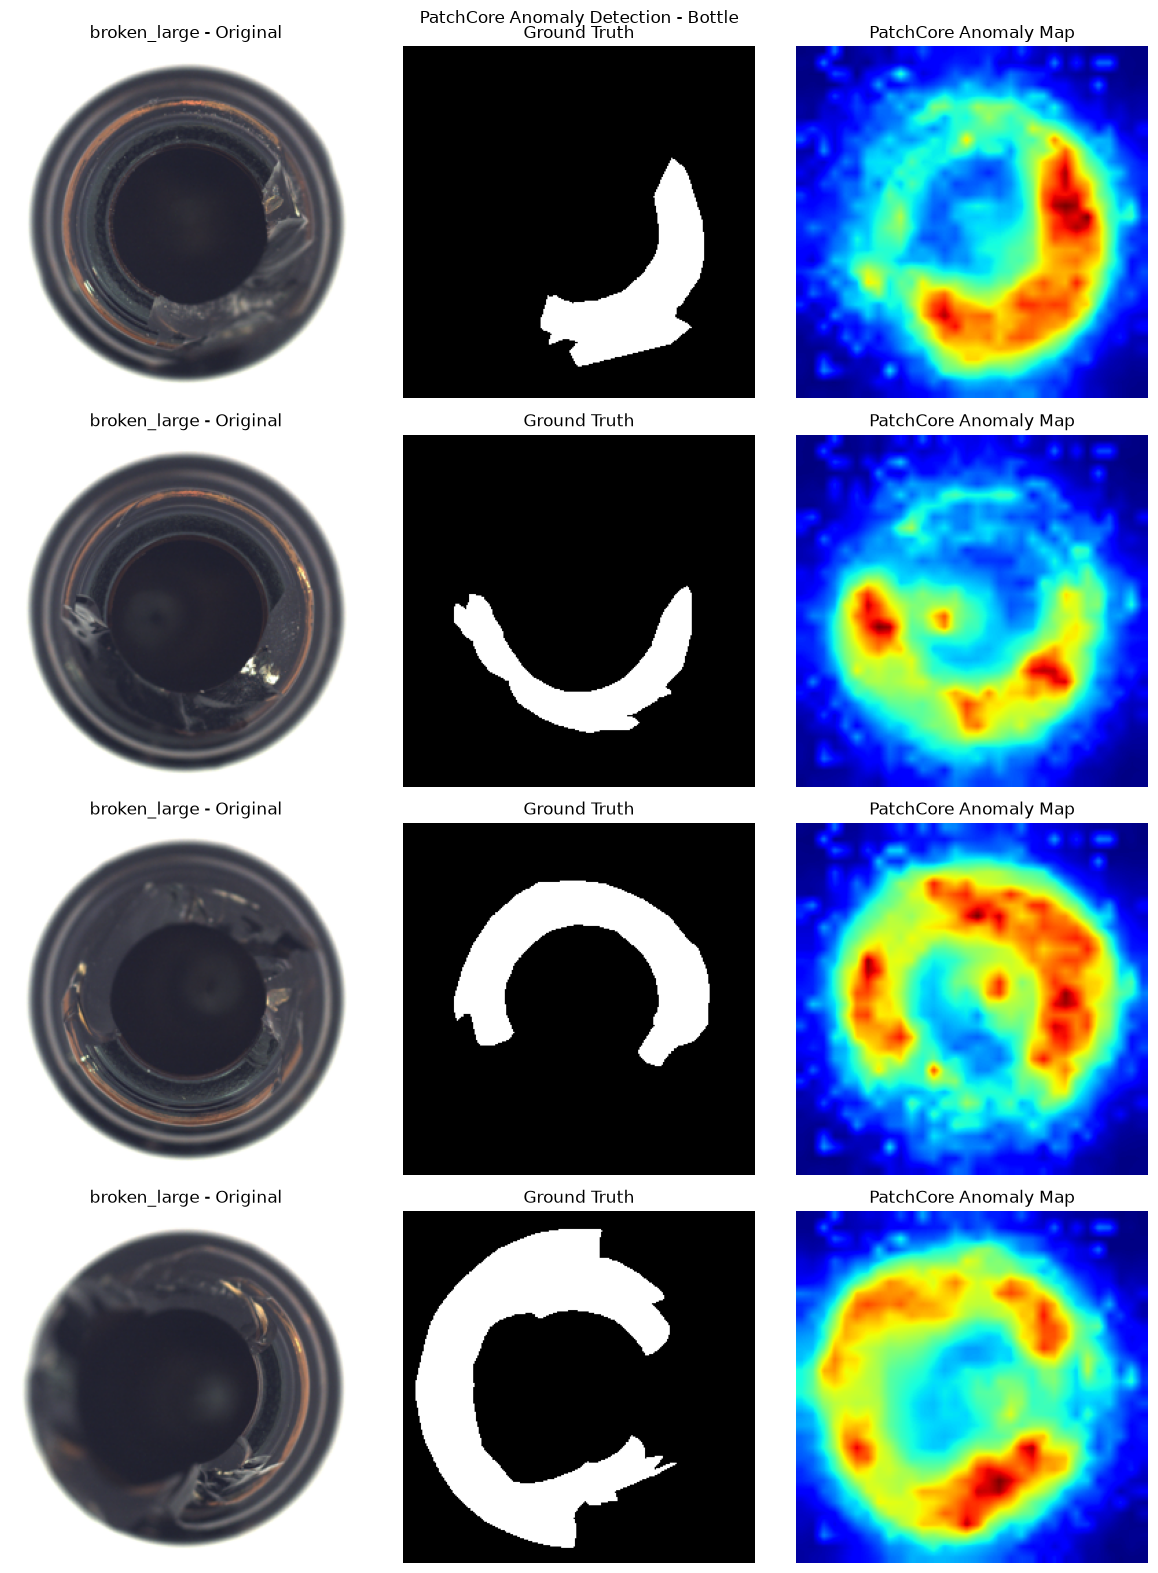

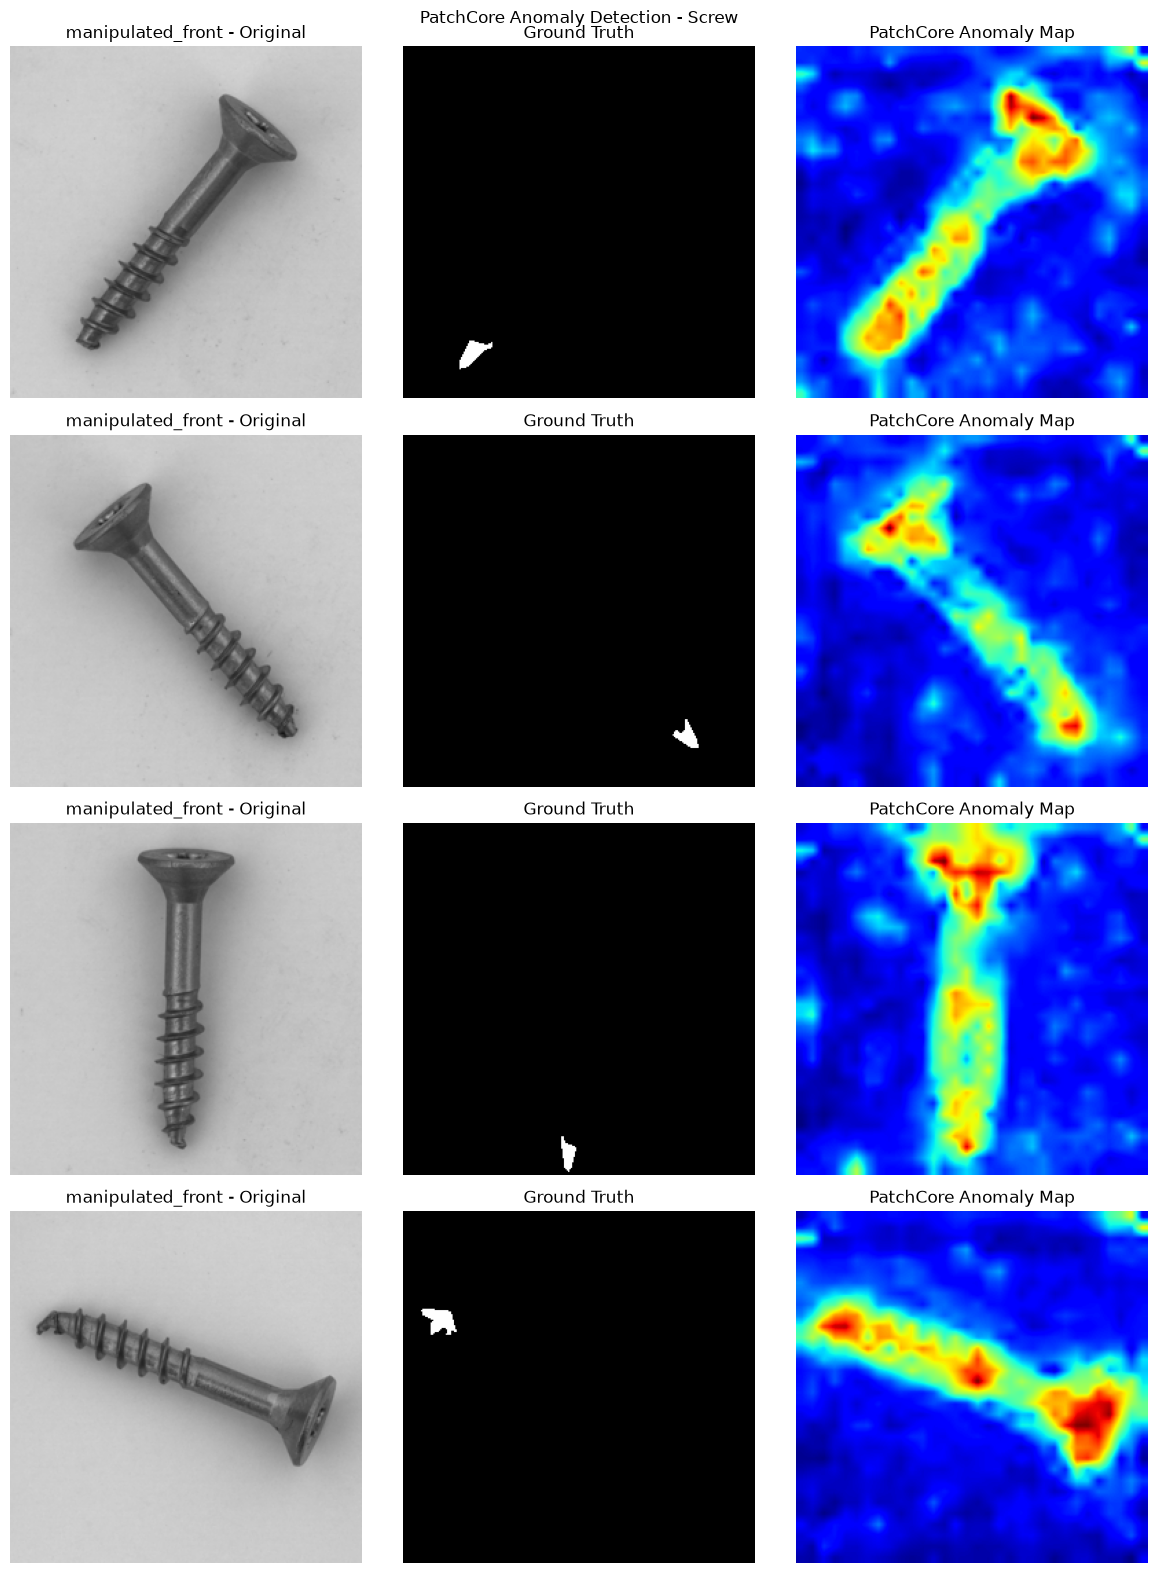


SAVED OUTPUT VERIFICATION
evaluation_report.json : True
evaluation_metrics.csv : True
bottle_anomaly_heatmaps.png : True
screw_anomaly_heatmaps.png : True

PATCHCORE EXPERIMENT COMPLETED.


In [9]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

INFERENCE_BANK_SIZE = 2000
PATCHCORE_DIR = Path("../models/patchcore")
OUTPUT_DIR = Path("../outputs/patchcore")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

categories = ["bottle", "screw"]

# --------------------------------------------------
# 2. Load saved normal memory banks
# --------------------------------------------------

inference_banks = {}

for category in categories:

    bank_path = PATCHCORE_DIR / f"{category}_memory_bank.pt"

    bank = torch.load(
        bank_path,
        map_location=device,
        weights_only=True
    )

    # Use a deterministic subset for efficient inference
    generator = torch.Generator().manual_seed(42)

    indices = torch.randperm(
        len(bank),
        generator=generator
    )[:INFERENCE_BANK_SIZE]

    inference_banks[category] = bank[indices].to(device)

    print(
        category,
        "inference memory bank:",
        tuple(inference_banks[category].shape)
    )

# --------------------------------------------------
# 3. Preprocessing
# --------------------------------------------------

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_test_image(image_path):

    image = Image.open(image_path).convert("RGB")

    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(image, dtype=np.float32) / 255.0
    image = (image - mean) / std

    tensor = torch.from_numpy(
        image.copy()
    ).permute(2, 0, 1).unsqueeze(0)

    return tensor


def load_ground_truth_mask(category, defect_type, image_path):

    # Normal images have no defect mask
    if defect_type == "good":
        return np.zeros(
            (IMAGE_SIZE, IMAGE_SIZE),
            dtype=np.uint8
        )

    mask_path = (
        DATASET_ROOT
        / category
        / "ground_truth"
        / defect_type
        / f"{image_path.stem}_mask.png"
    )

    if not mask_path.exists():
        raise FileNotFoundError(
            f"Ground-truth mask missing: {mask_path}"
        )

    mask = Image.open(mask_path).convert("L")

    mask = mask.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.NEAREST
    )

    mask = np.asarray(mask)

    return (mask > 0).astype(np.uint8)


# --------------------------------------------------
# 4. Nearest-neighbour anomaly scoring
# --------------------------------------------------

def calculate_anomaly_map(features, memory_bank):

    # features: [1024, 384]
    # memory_bank: [2000, 384]

    patch_scores = []

    # Process query patches in chunks to control VRAM
    for start in range(0, len(features), 128):

        query = features[start:start + 128]

        distances = torch.cdist(
            query.unsqueeze(0),
            memory_bank.unsqueeze(0),
            p=2
        )

        nearest_distances = distances.min(dim=2).values

        patch_scores.append(nearest_distances.squeeze(0))

    patch_scores = torch.cat(patch_scores)

    anomaly_map = patch_scores.reshape(1, 1, 32, 32)

    anomaly_map = F.interpolate(
        anomaly_map,
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False
    )

    return anomaly_map.squeeze().cpu().numpy()


# --------------------------------------------------
# 5. Evaluate Bottle and Screw
# --------------------------------------------------

all_results = {}

for category in categories:

    print("\n" + "=" * 55)
    print("PATCHCORE EVALUATION:", category.upper())
    print("=" * 55)

    test_dir = DATASET_ROOT / category / "test"

    category_results = []

    category_images = sorted(
        folder
        for folder in test_dir.iterdir()
        if folder.is_dir()
    )

    memory_bank = inference_banks[category]

    feature_extractor.eval()

    for defect_folder in category_images:

        defect_type = defect_folder.name

        image_paths = sorted(
            defect_folder.glob("*.png")
        )

        for image_path in image_paths:

            image_tensor = preprocess_test_image(
                image_path
            ).to(device)

            with torch.no_grad():

                features = feature_extractor(
                    image_tensor
                )

                features = features.permute(
                    0, 2, 3, 1
                ).reshape(-1, 384)

                anomaly_map = calculate_anomaly_map(
                    features,
                    memory_bank
                )

            ground_truth = load_ground_truth_mask(
                category,
                defect_type,
                image_path
            )

            image_label = int(defect_type != "good")

            image_score = float(anomaly_map.max())

            category_results.append({
                "category": category,
                "defect_type": defect_type,
                "filename": image_path.name,
                "image_label": image_label,
                "image_score": image_score,
                "anomaly_map": anomaly_map,
                "ground_truth": ground_truth
            })

        print(
            f"{defect_type}: {len(image_paths)} images processed"
        )

    all_results[category] = category_results

    print(
        "Total evaluated images:",
        len(category_results)
    )

print("\nANOMALY SCORING COMPLETED.")

# --------------------------------------------------
# 6. Calculate image-level and pixel-level AUROC
# --------------------------------------------------

evaluation_rows = []

for category in categories:

    results = all_results[category]

    image_labels = np.array([
        item["image_label"] for item in results
    ])

    image_scores = np.array([
        item["image_score"] for item in results
    ])

    image_auc = roc_auc_score(
        image_labels,
        image_scores
    )

    pixel_labels = np.concatenate([
        item["ground_truth"].reshape(-1)
        for item in results
    ])

    pixel_scores = np.concatenate([
        item["anomaly_map"].reshape(-1)
        for item in results
    ])

    pixel_auc = roc_auc_score(
        pixel_labels,
        pixel_scores
    )

    evaluation_rows.append({
        "Category": category.capitalize(),
        "Images": len(results),
        "Image AUROC": image_auc,
        "Pixel AUROC": pixel_auc
    })

    print(f"\n{category.upper()} RESULTS")
    print(f"Image AUROC: {image_auc:.4f}")
    print(f"Pixel AUROC: {pixel_auc:.4f}")

evaluation_df = pd.DataFrame(evaluation_rows)

print("\nPATCHCORE EVALUATION SUMMARY")
display(evaluation_df.round(4))

# --------------------------------------------------
# 7. Save evaluation metrics
# --------------------------------------------------

evaluation_report = {
    "method": "PatchCore-style ResNet18",
    "feature_extractor": "Pretrained ResNet18",
    "inference_memory_bank_size": INFERENCE_BANK_SIZE,
    "categories": evaluation_rows
}

with open(OUTPUT_DIR / "evaluation_report.json", "w") as f:
    json.dump(evaluation_report, f, indent=4)

evaluation_df.to_csv(
    OUTPUT_DIR / "evaluation_metrics.csv",
    index=False
)

# --------------------------------------------------
# 8. Visualize anomaly heatmaps
# --------------------------------------------------

for category in categories:

    results = all_results[category]

    # Prefer defective examples for visualization
    defective_results = [
        item for item in results
        if item["image_label"] == 1
    ]

    selected = defective_results[:4]

    fig, axes = plt.subplots(
        len(selected), 3,
        figsize=(12, 4 * len(selected))
    )

    if len(selected) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, item in enumerate(selected):

        original_path = (
            DATASET_ROOT
            / category
            / "test"
            / item["defect_type"]
            / item["filename"]
        )

        original = Image.open(
            original_path
        ).convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(
            f"{item['defect_type']} - Original"
        )

        axes[i, 1].imshow(
            item["ground_truth"],
            cmap="gray"
        )
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(
            item["anomaly_map"],
            cmap="jet"
        )
        axes[i, 2].set_title("PatchCore Anomaly Map")

        for ax in axes[i]:
            ax.axis("off")

    plt.suptitle(
        f"PatchCore Anomaly Detection - {category.capitalize()}"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{category}_anomaly_heatmaps.png",
        dpi=150
    )

    plt.show()

# --------------------------------------------------
# 9. Verify saved results
# --------------------------------------------------

print("\nSAVED OUTPUT VERIFICATION")

for filename in [
    "evaluation_report.json",
    "evaluation_metrics.csv",
    "bottle_anomaly_heatmaps.png",
    "screw_anomaly_heatmaps.png"
]:

    path = OUTPUT_DIR / filename

    print(filename, ":", path.exists())

print("\nPATCHCORE EXPERIMENT COMPLETED.")


In [10]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

scoring_results = []

for category in ["bottle", "screw"]:

    results = all_results[category]

    labels = np.array([
        item["image_label"] for item in results
    ])

    max_scores = []
    top1_scores = []
    top5_scores = []

    for item in results:

        scores = item["anomaly_map"].reshape(-1)

        max_scores.append(scores.max())

        top1_count = max(1, int(len(scores) * 0.01))
        top5_count = max(1, int(len(scores) * 0.05))

        top1_scores.append(
            np.mean(np.partition(scores, -top1_count)[-top1_count:])
        )

        top5_scores.append(
            np.mean(np.partition(scores, -top5_count)[-top5_count:])
        )

    for method, scores in [
        ("Maximum", max_scores),
        ("Top 1% Mean", top1_scores),
        ("Top 5% Mean", top5_scores)
    ]:

        auc = roc_auc_score(labels, scores)

        scoring_results.append({
            "Category": category.capitalize(),
            "Scoring Method": method,
            "Image AUROC": auc
        })

scoring_df = pd.DataFrame(scoring_results)

display(
    scoring_df.pivot(
        index="Category",
        columns="Scoring Method",
        values="Image AUROC"
    ).round(4)
)

scoring_df.to_csv(
    OUTPUT_DIR / "image_scoring_comparison.csv",
    index=False
)

print("Image scoring comparison saved.")


Scoring Method,Maximum,Top 1% Mean,Top 5% Mean
Category,,,
Bottle,0.9746,0.9937,0.9976
Screw,0.5813,0.6149,0.6270


Image scoring comparison saved.


In [11]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

def top_percent_score(anomaly_map, percentage=0.05):

    scores = anomaly_map.reshape(-1)

    count = max(
        1,
        int(len(scores) * percentage)
    )

    return float(
        np.partition(scores, -count)[-count:].mean()
    )


def evaluate_defect_types(category):

    results = all_results[category]

    rows = []

    defect_types = sorted(set(
        item["defect_type"] for item in results
    ))

    for defect_type in defect_types:

        if defect_type == "good":
            continue

        selected = [
            item for item in results
            if item["defect_type"] in ["good", defect_type]
        ]

        labels = np.array([
            item["image_label"] for item in selected
        ])

        scores = np.array([
            top_percent_score(item["anomaly_map"], 0.05)
            for item in selected
        ])

        auc = roc_auc_score(labels, scores)

        rows.append({
            "Defect Category": defect_type,
            "Defective Images": sum(labels == 1),
            "Normal Images": sum(labels == 0),
            "Image AUROC": auc
        })

    return pd.DataFrame(rows)


# --------------------------------------------------
# Evaluate both products
# --------------------------------------------------

bottle_defect_results = evaluate_defect_types("bottle")
screw_defect_results = evaluate_defect_types("screw")

print("=" * 55)
print("BOTTLE DEFECT-WISE IMAGE AUROC")
print("=" * 55)

display(bottle_defect_results.round(4))

print("\n" + "=" * 55)
print("SCREW DEFECT-WISE IMAGE AUROC")
print("=" * 55)

display(screw_defect_results.round(4))


# --------------------------------------------------
# Save reports
# --------------------------------------------------

bottle_defect_results.to_csv(
    OUTPUT_DIR / "bottle_defect_wise_auc.csv",
    index=False
)

screw_defect_results.to_csv(
    OUTPUT_DIR / "screw_defect_wise_auc.csv",
    index=False
)

print("\nDefect-wise evaluation reports saved.")


BOTTLE DEFECT-WISE IMAGE AUROC


,Defect Category,Defective Images,Normal Images,Image AUROC
0,broken_large,20,20,1.0000
1,broken_small,22,20,1.0000
2,contamination,21,20,0.9929



SCREW DEFECT-WISE IMAGE AUROC


,Defect Category,Defective Images,Normal Images,Image AUROC
0,manipulated_front,24,41,0.6413
1,scratch_head,24,41,0.6809
2,scratch_neck,25,41,0.5571
3,thread_side,23,41,0.5323
4,thread_top,23,41,0.7264



Defect-wise evaluation reports saved.


SCREW IMAGE SCORE SUMMARY


,,count,mean,median,std,min,max
Defect Type,Label,,,,,,
good,Normal,41,4.2505,4.2353,0.1114,3.9932,4.5439
manipulated_front,Defective,24,4.3122,4.3273,0.1515,4.0483,4.6063
scratch_head,Defective,24,4.3466,4.3665,0.1533,4.0855,4.6349
scratch_neck,Defective,25,4.2744,4.2853,0.1402,3.9553,4.5354
thread_side,Defective,23,4.2716,4.2506,0.1610,4.0225,4.6390
thread_top,Defective,23,4.3486,4.3401,0.1338,4.0631,4.5888


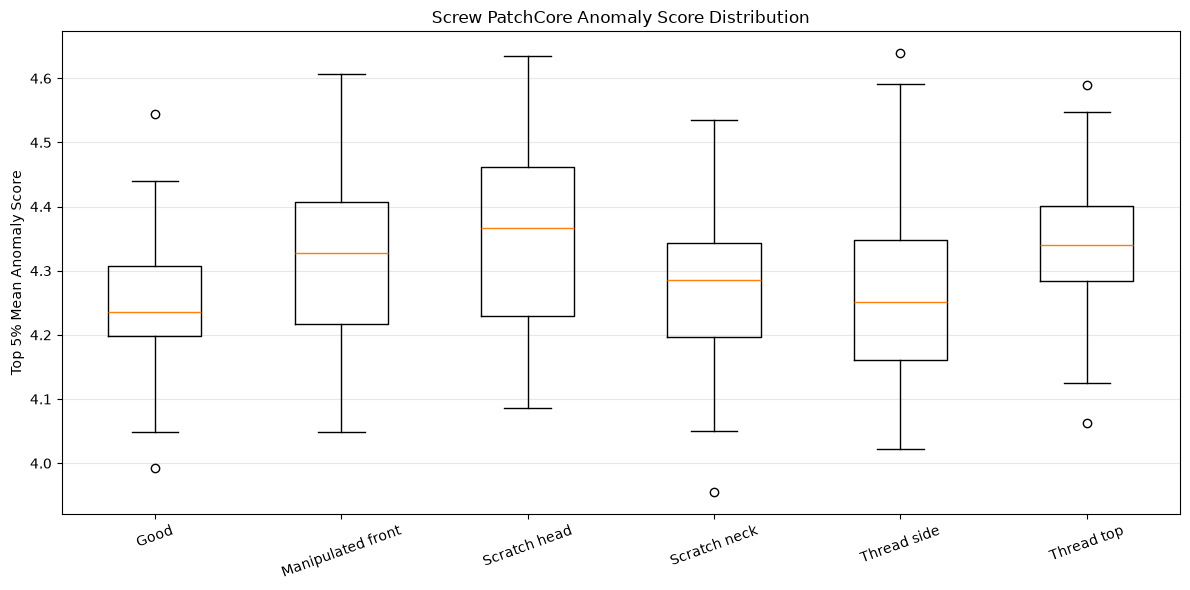

Score distribution plot saved.


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def top5_score(anomaly_map):
    scores = anomaly_map.reshape(-1)
    count = max(1, int(len(scores) * 0.05))
    return float(np.partition(scores, -count)[-count:].mean())


# --------------------------------------------------
# Collect Screw anomaly scores
# --------------------------------------------------

screw_results = all_results["screw"]

distribution_data = []

for item in screw_results:

    distribution_data.append({
        "Defect Type": item["defect_type"],
        "Image Score": top5_score(item["anomaly_map"]),
        "Label": "Normal" if item["image_label"] == 0 else "Defective"
    })

score_df = pd.DataFrame(distribution_data)

print("SCREW IMAGE SCORE SUMMARY")
display(
    score_df.groupby(
        ["Defect Type", "Label"]
    )["Image Score"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(4)
)

# --------------------------------------------------
# Boxplot: Normal vs defective
# --------------------------------------------------

plt.figure(figsize=(12, 6))

plot_data = [
    score_df.loc[
        score_df["Defect Type"] == defect,
        "Image Score"
    ].values
    for defect in [
        "good",
        "manipulated_front",
        "scratch_head",
        "scratch_neck",
        "thread_side",
        "thread_top"
    ]
]

plt.boxplot(
    plot_data,
    tick_labels=[
        "Good",
        "Manipulated front",
        "Scratch head",
        "Scratch neck",
        "Thread side",
        "Thread top"
    ]
)

plt.title("Screw PatchCore Anomaly Score Distribution")
plt.ylabel("Top 5% Mean Anomaly Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "screw_score_distribution.png",
    dpi=150
)

plt.show()

print("Score distribution plot saved.")


In [13]:

# RESTORE PATCHCORE EVALUATION RESULTS

import numpy as np
import torch
from pathlib import Path

categories = ["bottle", "screw"]

all_results = {}

for category in categories:

    print("\nRestoring:", category.upper())

    test_dir = DATASET_ROOT / category / "test"

    category_results = []

    defect_folders = sorted(
        folder for folder in test_dir.iterdir()
        if folder.is_dir()
    )

    for defect_folder in defect_folders:

        defect_type = defect_folder.name

        image_paths = sorted(
            defect_folder.glob("*.png")
        )

        for image_path in image_paths:

            image_tensor = preprocess_test_image(
                image_path
            ).to(device)

            with torch.no_grad():

                features = feature_extractor(image_tensor)

                features = features.permute(
                    0, 2, 3, 1
                ).reshape(-1, 384)

                anomaly_map = calculate_anomaly_map(
                    features,
                    inference_banks[category]
                )

            ground_truth = load_ground_truth_mask(
                category,
                defect_type,
                image_path
            )

            category_results.append({
                "category": category,
                "defect_type": defect_type,
                "filename": image_path.name,
                "image_label": int(defect_type != "good"),
                "image_score": float(anomaly_map.max()),
                "anomaly_map": anomaly_map,
                "ground_truth": ground_truth
            })

        print(
            defect_type,
            ":",
            len(image_paths),
            "images restored"
        )

    all_results[category] = category_results

    print(
        "Total:",
        len(category_results)
    )

print("\nPATCHCORE RESULTS RESTORED SUCCESSFULLY.")

assert len(all_results["bottle"]) == 83
assert len(all_results["screw"]) == 160

print("Bottle:", len(all_results["bottle"]))
print("Screw:", len(all_results["screw"]))



Restoring: BOTTLE
broken_large : 20 images restored
broken_small : 22 images restored
contamination : 21 images restored
good : 20 images restored
Total: 83

Restoring: SCREW
good : 41 images restored
manipulated_front : 24 images restored
scratch_head : 24 images restored
scratch_neck : 25 images restored
thread_side : 23 images restored
thread_top : 23 images restored
Total: 160

PATCHCORE RESULTS RESTORED SUCCESSFULLY.
Bottle: 83
Screw: 160


SCREW IMAGE-LEVEL AUROC COMPARISON


,Scoring Method,Image AUROC
0,Original Top 5%,0.6270
1,Foreground-only Top 5%,0.6141


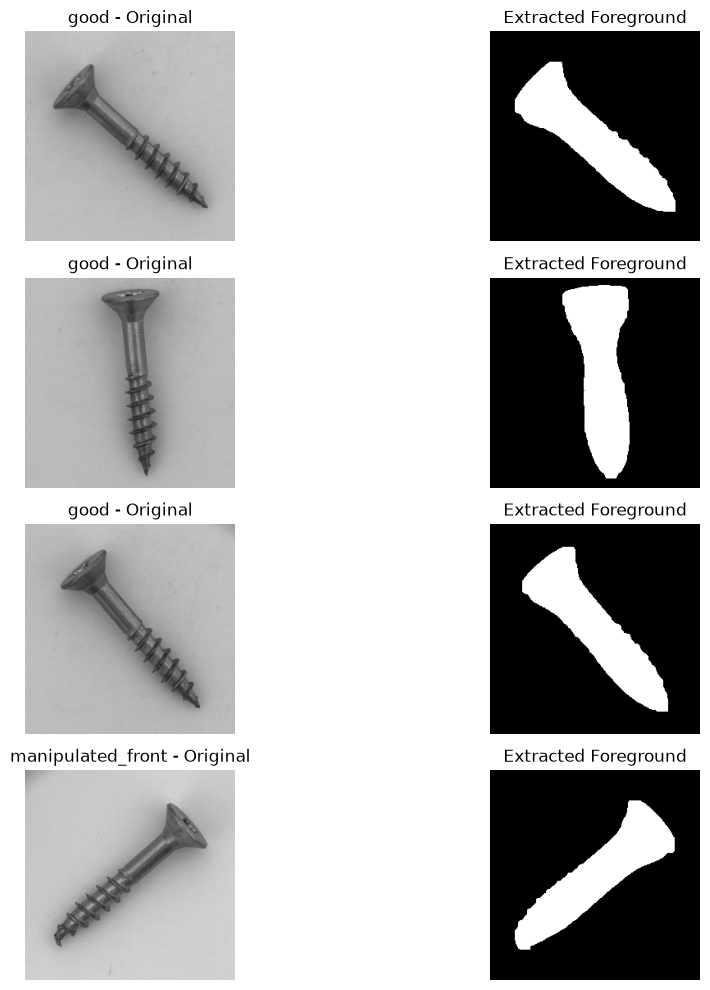

Foreground experiment saved.


In [14]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 1. Extract screw foreground
# --------------------------------------------------

def create_screw_foreground_mask(image_path):

    image = cv2.imread(str(image_path))

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(
        gray,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    kernel = np.ones((5, 5), np.uint8)

    binary = cv2.morphologyEx(
        binary, cv2.MORPH_CLOSE, kernel
    )

    binary = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN, kernel
    )

    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary,
            connectivity=8
        )
    )

    if count <= 1:
        return np.ones(
            (IMAGE_SIZE, IMAGE_SIZE),
            dtype=bool
        )

    largest = 1 + np.argmax(
        stats[1:, cv2.CC_STAT_AREA]
    )

    foreground = (labels == largest).astype(np.uint8)

    foreground = cv2.dilate(
        foreground,
        np.ones((5, 5), np.uint8),
        iterations=2
    )

    return foreground.astype(bool)


# --------------------------------------------------
# 2. Calculate original and foreground scores
# --------------------------------------------------

def top5_score(anomaly_map):

    scores = anomaly_map.reshape(-1)

    count = max(1, int(len(scores) * 0.05))

    return float(
        np.partition(scores, -count)[-count:].mean()
    )


foreground_results = []

for item in all_results["screw"]:

    image_path = (
        DATASET_ROOT
        / "screw"
        / "test"
        / item["defect_type"]
        / item["filename"]
    )

    foreground_mask = create_screw_foreground_mask(
        image_path
    )

    anomaly_map = item["anomaly_map"]

    foreground_scores = anomaly_map[foreground_mask]

    count = max(
        1,
        int(len(foreground_scores) * 0.05)
    )

    foreground_score = float(
        np.partition(
            foreground_scores,
            -count
        )[-count:].mean()
    )

    foreground_results.append({
        "Defect Type": item["defect_type"],
        "Label": item["image_label"],
        "Original Score": top5_score(anomaly_map),
        "Foreground Score": foreground_score,
        "Foreground Mask": foreground_mask
    })


# --------------------------------------------------
# 3. Compare image AUROC
# --------------------------------------------------

labels = np.array([
    item["Label"] for item in foreground_results
])

original_scores = np.array([
    item["Original Score"] for item in foreground_results
])

foreground_scores = np.array([
    item["Foreground Score"] for item in foreground_results
])

original_auc = roc_auc_score(labels, original_scores)

foreground_auc = roc_auc_score(labels, foreground_scores)

comparison = pd.DataFrame({
    "Scoring Method": [
        "Original Top 5%",
        "Foreground-only Top 5%"
    ],
    "Image AUROC": [
        original_auc,
        foreground_auc
    ]
})

print("SCREW IMAGE-LEVEL AUROC COMPARISON")
display(comparison.round(4))


# --------------------------------------------------
# 4. Visualize foreground extraction
# --------------------------------------------------

selected_indices = [0, 10, 25, 50]

plt.figure(figsize=(12, 10))

for row, idx in enumerate(selected_indices):

    item = all_results["screw"][idx]

    mask = foreground_results[idx]["Foreground Mask"]

    image_path = (
        DATASET_ROOT
        / "screw"
        / "test"
        / item["defect_type"]
        / item["filename"]
    )

    image = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    plt.subplot(4, 2, row * 2 + 1)
    plt.imshow(image)
    plt.title(item["defect_type"] + " - Original")
    plt.axis("off")

    plt.subplot(4, 2, row * 2 + 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Extracted Foreground")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "screw_foreground_masks.png",
    dpi=150
)

plt.show()


# --------------------------------------------------
# 5. Save experiment results
# --------------------------------------------------

comparison.to_csv(
    OUTPUT_DIR / "screw_foreground_scoring_comparison.csv",
    index=False
)

print("Foreground experiment saved.")


SCREW IMAGE-LEVEL AUROC COMPARISON


,Scoring Method,Image AUROC
0,Original Top 5%,0.6270
1,Foreground-only Top 5%,0.6141


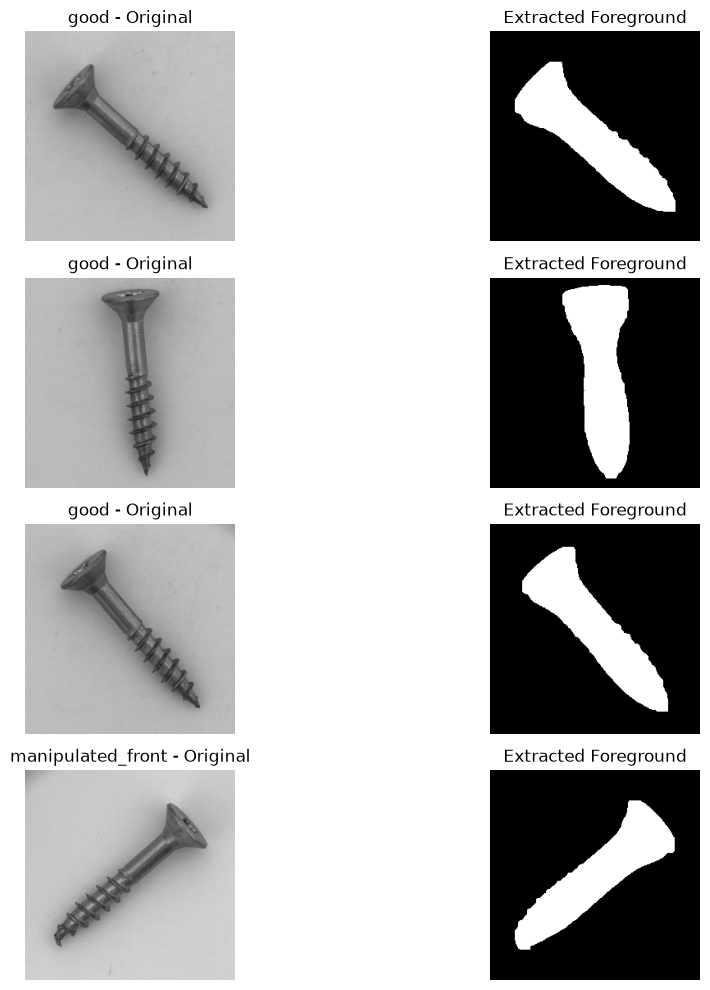

Foreground experiment saved.


In [33]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 1. Extract screw foreground
# --------------------------------------------------

def create_screw_foreground_mask(image_path):

    image = cv2.imread(str(image_path))

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(
        gray,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    kernel = np.ones((5, 5), np.uint8)

    binary = cv2.morphologyEx(
        binary, cv2.MORPH_CLOSE, kernel
    )

    binary = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN, kernel
    )

    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary,
            connectivity=8
        )
    )

    if count <= 1:
        return np.ones(
            (IMAGE_SIZE, IMAGE_SIZE),
            dtype=bool
        )

    largest = 1 + np.argmax(
        stats[1:, cv2.CC_STAT_AREA]
    )

    foreground = (labels == largest).astype(np.uint8)

    foreground = cv2.dilate(
        foreground,
        np.ones((5, 5), np.uint8),
        iterations=2
    )

    return foreground.astype(bool)


# --------------------------------------------------
# 2. Calculate original and foreground scores
# --------------------------------------------------

def top5_score(anomaly_map):

    scores = anomaly_map.reshape(-1)

    count = max(1, int(len(scores) * 0.05))

    return float(
        np.partition(scores, -count)[-count:].mean()
    )


foreground_results = []

for item in all_results["screw"]:

    image_path = (
        DATASET_ROOT
        / "screw"
        / "test"
        / item["defect_type"]
        / item["filename"]
    )

    foreground_mask = create_screw_foreground_mask(
        image_path
    )

    anomaly_map = item["anomaly_map"]

    foreground_scores = anomaly_map[foreground_mask]

    count = max(
        1,
        int(len(foreground_scores) * 0.05)
    )

    foreground_score = float(
        np.partition(
            foreground_scores,
            -count
        )[-count:].mean()
    )

    foreground_results.append({
        "Defect Type": item["defect_type"],
        "Label": item["image_label"],
        "Original Score": top5_score(anomaly_map),
        "Foreground Score": foreground_score,
        "Foreground Mask": foreground_mask
    })


# --------------------------------------------------
# 3. Compare image AUROC
# --------------------------------------------------

labels = np.array([
    item["Label"] for item in foreground_results
])

original_scores = np.array([
    item["Original Score"] for item in foreground_results
])

foreground_scores = np.array([
    item["Foreground Score"] for item in foreground_results
])

original_auc = roc_auc_score(labels, original_scores)

foreground_auc = roc_auc_score(labels, foreground_scores)

comparison = pd.DataFrame({
    "Scoring Method": [
        "Original Top 5%",
        "Foreground-only Top 5%"
    ],
    "Image AUROC": [
        original_auc,
        foreground_auc
    ]
})

print("SCREW IMAGE-LEVEL AUROC COMPARISON")
display(comparison.round(4))


# --------------------------------------------------
# 4. Visualize foreground extraction
# --------------------------------------------------

selected_indices = [0, 10, 25, 50]

plt.figure(figsize=(12, 10))

for row, idx in enumerate(selected_indices):

    item = all_results["screw"][idx]

    mask = foreground_results[idx]["Foreground Mask"]

    image_path = (
        DATASET_ROOT
        / "screw"
        / "test"
        / item["defect_type"]
        / item["filename"]
    )

    image = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    plt.subplot(4, 2, row * 2 + 1)
    plt.imshow(image)
    plt.title(item["defect_type"] + " - Original")
    plt.axis("off")

    plt.subplot(4, 2, row * 2 + 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Extracted Foreground")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "screw_foreground_masks.png",
    dpi=150
)

plt.show()


# --------------------------------------------------
# 5. Save experiment results
# --------------------------------------------------

comparison.to_csv(
    OUTPUT_DIR / "screw_foreground_scoring_comparison.csv",
    index=False
)

print("Foreground experiment saved.")


In [34]:

from pathlib import Path
import random
import pandas as pd
import json

# ==========================================
# 1. CONFIGURATION
# ==========================================

ROOT = Path(r"D:\VisionInspect-AI\datasets\mvtec_ad")
CATEGORY = "bottle"
SEED = 42

OUTPUT_DIR = Path(r"D:\VisionInspect-AI\outputs\manifests")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE = ROOT / CATEGORY

assert BASE.exists(), f"Bottle dataset not found: {BASE}"

random.seed(SEED)

print("Dataset:", BASE)
print("Output:", OUTPUT_DIR)


# ==========================================
# 2. SPLIT FUNCTION FOR DEFECT IMAGES
# ==========================================

def choose_splits(paths, seed=42):
    paths = sorted(paths)
    paths = list(paths)

    if len(paths) < 3:
        raise ValueError(
            f"Not enough images for train/val/test: {len(paths)}"
        )

    rng = random.Random(seed)
    rng.shuffle(paths)

    n = len(paths)

    n_val = max(1, round(n * 0.20))
    n_test = max(1, round(n * 0.20))

    if n_val + n_test >= n:
        raise ValueError("Unable to create three valid splits.")

    train = paths[:n - n_val - n_test]
    val = paths[n - n_val - n_test:n - n_test]
    test = paths[n - n_test:]

    return train, val, test


# ==========================================
# 3. CREATE MANIFEST RECORDS
# ==========================================

rows = []

def record(img, split, defect_type="good", mask=None):
    rows.append({
        "image_path": str(img),
        "mask_path": str(mask) if mask else "",
        "category": CATEGORY,
        "defect_type": defect_type,
        "is_anomaly": int(defect_type != "good"),
        "project_split": split
    })


# ==========================================
# 4. NORMAL TRAINING IMAGES: 85/15
# ==========================================

good_train = sorted(
    (BASE / "train" / "good").glob("*.png")
)

assert len(good_train) >= 2, "Not enough normal training images."

rng = random.Random(SEED)
rng.shuffle(good_train)

cut = round(len(good_train) * 0.85)
cut = max(1, min(cut, len(good_train) - 1))

for img in good_train[:cut]:
    record(img, "train")

for img in good_train[cut:]:
    record(img, "val")


# ==========================================
# 5. ORIGINAL NORMAL TEST IMAGES
# ==========================================

good_test = sorted(
    (BASE / "test" / "good").glob("*.png")
)

for img in good_test:
    record(img, "test")


# ==========================================
# 6. DEFECT IMAGES: 60/20/20
# ==========================================

test_dir = BASE / "test"

defect_folders = sorted([
    folder for folder in test_dir.iterdir()
    if folder.is_dir() and folder.name != "good"
])

for defect_dir in defect_folders:

    defect_type = defect_dir.name

    images = sorted(defect_dir.glob("*.png"))

    train_imgs, val_imgs, test_imgs = choose_splits(
        images,
        seed=SEED
    )

    for split, selected_images in [
        ("train", train_imgs),
        ("val", val_imgs),
        ("test", test_imgs)
    ]:

        for img in selected_images:

            mask = (
                BASE / "ground_truth" /
                defect_type / f"{img.stem}_mask.png"
            )

            assert mask.is_file(), (
                f"Missing ground-truth mask: {mask}"
            )

            record(
                img,
                split,
                defect_type,
                mask
            )


# ==========================================
# 7. BUILD AND VERIFY DATAFRAME
# ==========================================

df = pd.DataFrame(rows)

assert df["image_path"].is_unique, (
    "Duplicate image found across splits!"
)

assert set(df["project_split"]) == {
    "train", "val", "test"
}

# Verify every defective image has a mask
defect_rows = df[df["is_anomaly"] == 1]

assert defect_rows["mask_path"].ne("").all()

assert all(
    Path(path).is_file()
    for path in defect_rows["mask_path"]
)

# ==========================================
# 8. SAVE MANIFEST
# ==========================================

manifest_path = OUTPUT_DIR / "bottle_custom_split.csv"

df.to_csv(manifest_path, index=False)


# ==========================================
# 9. SAVE SPLIT SUMMARY
# ==========================================

summary = (
    df.groupby(
        ["project_split", "defect_type", "is_anomaly"]
    )
    .size()
    .reset_index(name="image_count")
)

summary_path = OUTPUT_DIR / "bottle_split_summary.csv"
summary.to_csv(summary_path, index=False)

metadata = {
    "category": CATEGORY,
    "random_seed": SEED,
    "protocol": "custom_supervised_split_v1",
    "defect_split": "60/20/20",
    "normal_train_split": "85/15",
    "normal_test": "100% of original test/good",
    "total_images": len(df),
    "manifest": str(manifest_path)
}

with open(
    OUTPUT_DIR / "bottle_split_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)


# ==========================================
# 10. DISPLAY RESULTS
# ==========================================

print("\n========== BOTTLE MANIFEST CREATED ==========")

print("\nSplit counts:")
print(df["project_split"].value_counts())

print("\nDetailed category distribution:")
print(summary.to_string(index=False))

print("\nTotal images:", len(df))
print("\nManifest saved:", manifest_path)
print("Summary saved:", summary_path)

print("\nAll integrity checks passed!")


Dataset: D:\VisionInspect-AI\datasets\mvtec_ad\bottle
Output: D:\VisionInspect-AI\outputs\manifests

========== BOTTLE MANIFEST CREATED ==========

Split counts:
project_split
train    217
val       43
test      32
Name: count, dtype: int64

Detailed category distribution:
project_split   defect_type  is_anomaly  image_count
         test  broken_large           1            4
         test  broken_small           1            4
         test contamination           1            4
         test          good           0           20
        train  broken_large           1           12
        train  broken_small           1           14
        train contamination           1           13
        train          good           0          178
          val  broken_large           1            4
          val  broken_small           1            4
          val contamination           1            4
          val          good           0           31

Total images: 292

Manifest saved: D

In [35]:

# ============================================================
# BOTTLE DATASET LOADER
# VisionInspect AI
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MANIFEST_PATH = Path(
    r"D:\VisionInspect-AI\outputs\manifests\bottle_custom_split.csv"
)

IMAGE_SIZE = 256
BATCH_SIZE = 4
RANDOM_SEED = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert MANIFEST_PATH.is_file(), "Manifest file not found!"

print("Device:", device)
print("Manifest:", MANIFEST_PATH)


# ------------------------------------------------------------
# 2. LOAD MANIFEST
# ------------------------------------------------------------

df = pd.read_csv(MANIFEST_PATH).fillna("")

print("\nManifest loaded successfully!")
print("Total images:", len(df))

print("\nSplit distribution:")
print(df["project_split"].value_counts())


# ------------------------------------------------------------
# 3. CREATE PYTORCH DATASET CLASS
# ------------------------------------------------------------

class BottleDataset(Dataset):

    def __init__(self, dataframe, image_size=256):

        self.data = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        # Load original product image
        image_path = Path(row["image_path"])

        with Image.open(image_path) as img:
            image = img.convert("RGB").resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )

        image = np.asarray(image, dtype=np.float32) / 255.0

        # Load defect mask or create an empty mask
        if int(row["is_anomaly"]) == 1:

            mask_path = Path(row["mask_path"])

            with Image.open(mask_path) as mask_img:
                mask = mask_img.convert("L").resize(
                    (self.image_size, self.image_size),
                    Image.Resampling.NEAREST
                )

            mask = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)

        else:

            mask = np.zeros(
                (self.image_size, self.image_size),
                dtype=np.float32
            )

        # Convert image: HWC -> CHW
        image_tensor = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1).float()

        # Convert mask: HW -> 1HW
        mask_tensor = torch.from_numpy(
            mask.copy()
        ).unsqueeze(0).float()

        return image_tensor, mask_tensor


# ------------------------------------------------------------
# 4. SEPARATE TRAIN, VALIDATION AND TEST DATA
# ------------------------------------------------------------

train_df = df[df["project_split"] == "train"]
val_df = df[df["project_split"] == "val"]
test_df = df[df["project_split"] == "test"]

train_dataset = BottleDataset(train_df, IMAGE_SIZE)
val_dataset = BottleDataset(val_df, IMAGE_SIZE)
test_dataset = BottleDataset(test_df, IMAGE_SIZE)

print("\nDatasets created:")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


# ------------------------------------------------------------
# 5. CREATE DATALOADERS
# ------------------------------------------------------------

generator = torch.Generator()
generator.manual_seed(RANDOM_SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ------------------------------------------------------------
# 6. VERIFY ONE BATCH
# ------------------------------------------------------------

images, masks = next(iter(train_loader))

print("\n========== BATCH VERIFICATION ==========")

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image pixel range:",
      images.min().item(),
      "to",
      images.max().item())

print("Mask unique values:", torch.unique(masks))

print("\n========== DATALOADER SUMMARY ==========")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nBottle dataset preparation completed!")


Device: cuda
Manifest: D:\VisionInspect-AI\outputs\manifests\bottle_custom_split.csv

Manifest loaded successfully!
Total images: 292

Split distribution:
project_split
train    217
val       43
test      32
Name: count, dtype: int64

Datasets created:
Training samples: 217
Validation samples: 43
Testing samples: 32

========== BATCH VERIFICATION ==========
Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.float32
Image pixel range: 0.11372549086809158 to 1.0
Mask unique values: tensor([0.])

========== DATALOADER SUMMARY ==========
Training batches: 55
Validation batches: 11
Testing batches: 8

Bottle dataset preparation completed!


In [36]:

# Verify normal and defective masks across the full dataset

normal_count = 0
defective_count = 0
empty_masks = 0
nonempty_masks = 0

for images, masks in DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
):

    for mask in masks:

        if mask.sum().item() > 0:
            nonempty_masks += 1
            defective_count += 1
        else:
            empty_masks += 1
            normal_count += 1

print("========== MASK VERIFICATION ==========")
print("Normal images:", normal_count)
print("Defective images:", defective_count)
print("Empty masks:", empty_masks)
print("Non-empty masks:", nonempty_masks)

assert normal_count + defective_count == len(train_dataset)
assert defective_count > 0
assert normal_count > 0

print("\nMask verification successful!")


========== MASK VERIFICATION ==========
Normal images: 178
Defective images: 39
Empty masks: 178
Non-empty masks: 39

Mask verification successful!


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Training images: 217
Validation images: 43
Training normal/defect counts: [178, 39]

U-Net created successfully!
Trainable parameters: 7765985

========== TRAINING STARTED ==========
Epoch [01/40] Loss: 1.3696 | Val Dice: 0.2598 | Val IoU: 0.1493 | Normal FAR: 100.00%
  -> Best checkpoint saved!
Epoch [02/40] Loss: 1.2344 | Val Dice: 0.7164 | Val IoU: 0.5581 | Normal FAR: 100.00%
  -> Best checkpoint saved!
Epoch [03/40] Loss: 1.1272 | Val Dice: 0.7594 | Val IoU: 0.6122 | Normal FAR: 16.13%
  -> Best checkpoint saved!
Epoch [04/40] Loss: 1.0862 | Val Dice: 0.7376 | Val IoU: 0.5843 | Normal FAR: 48.39%
Epoch [05/40] Loss: 1.0810 | Val Dice: 0.7294 | Val IoU: 0.5740 | Normal FAR: 80.65%
Epoch [06/40] Loss: 1.0173 | Val Dice: 0.8062 | Val IoU: 0.6753 | Normal FAR: 25.81%
  -> Best checkpoint saved!
Epoch [07/40] Loss: 1.0236 | Val Dice: 0.8316 | Val IoU: 0.7118 | Normal FAR: 19.35%
  -> Best checkpoint saved!
Epoch [08/40] Loss: 0.9325 

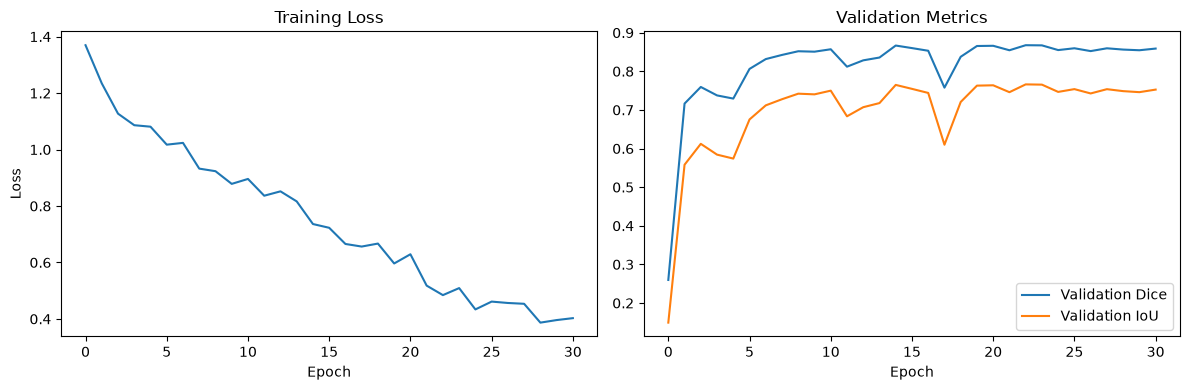


========== TRAINING COMPLETED ==========
Best validation Dice: 0.8676
Checkpoint: D:\VisionInspect-AI\models\bottle_unet_corrected_best.pth
History: D:\VisionInspect-AI\outputs\bottle_unet_corrected\training_history.json
Training curves: D:\VisionInspect-AI\outputs\bottle_unet_corrected\training_curves.png


In [37]:

# ============================================================
# VISIONINSPECT AI - BOTTLE U-NET TRAINING
# Corrected custom train / validation / test protocol
# ============================================================

from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 40
LEARNING_RATE = 0.0001
PATIENCE = 8

ROOT = Path(r"D:\VisionInspect-AI")
MANIFEST = ROOT / "outputs/manifests/bottle_custom_split.csv"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs/bottle_unet_corrected"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "bottle_unet_corrected_best.pth"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. DATASET
# ------------------------------------------------------------

class BottleDataset(Dataset):

    def __init__(self, dataframe, image_size=256):
        self.data = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB").resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )

        image = np.asarray(image, dtype=np.float32) / 255.0

        if int(row["is_anomaly"]) == 1:
            with Image.open(row["mask_path"]) as mask_img:
                mask = mask_img.convert("L").resize(
                    (self.image_size, self.image_size),
                    Image.Resampling.NEAREST
                )

            mask = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)
        else:
            mask = np.zeros(
                (self.image_size, self.image_size),
                dtype=np.float32
            )

        image_tensor = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1).float()

        mask_tensor = torch.from_numpy(
            mask.copy()
        ).unsqueeze(0).float()

        return image_tensor, mask_tensor


# ------------------------------------------------------------
# 3. LOAD THE MANIFEST AND CREATE DATA LOADERS
# ------------------------------------------------------------

df = pd.read_csv(MANIFEST).fillna("")

train_df = df[df.project_split == "train"].copy()
val_df = df[df.project_split == "val"].copy()

# Do not load or iterate over test_df during training.
train_dataset = BottleDataset(train_df, IMAGE_SIZE)
val_dataset = BottleDataset(val_df, IMAGE_SIZE)

# Balance normal and defective images during training.
labels = train_df["is_anomaly"].astype(int).to_numpy()
class_counts = np.bincount(labels, minlength=2)

sample_weights = np.array([
    1.0 / class_counts[label] for label in labels
], dtype=np.float64)

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training normal/defect counts:", class_counts.tolist())


# ------------------------------------------------------------
# 4. U-NET ARCHITECTURE
# ------------------------------------------------------------

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)


model = UNet().to(device)

print("\nU-Net created successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


# ------------------------------------------------------------
# 5. BCE + DICE LOSS
# ------------------------------------------------------------

bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, epsilon=1e-6):

    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (probabilities * targets).sum(dim=1)

    denominator = (
        probabilities.sum(dim=1) + targets.sum(dim=1)
    )

    dice = (
        2 * intersection + epsilon
    ) / (
        denominator + epsilon
    )

    # Exclude empty-mask images from Dice loss.
    positive_images = targets.sum(dim=1) > 0

    if positive_images.any():
        return 1 - dice[positive_images].mean()

    return logits.sum() * 0.0


def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)


# ------------------------------------------------------------
# 6. VALIDATION METRICS
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_validation(model, loader, threshold=0.5):

    model.eval()

    tp = fp = fn = 0
    normal_images = 0
    normal_false_alarm_images = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = torch.sigmoid(logits) >= threshold
        targets = masks >= 0.5

        for i in range(images.size(0)):

            pred = predictions[i]
            target = targets[i]

            if target.sum().item() == 0:
                normal_images += 1

                if pred.any().item():
                    normal_false_alarm_images += 1

                continue

            tp += (pred & target).sum().item()
            fp += (pred & ~target).sum().item()
            fn += (~pred & target).sum().item()

    dice = (2 * tp) / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)

    normal_far = (
        normal_false_alarm_images / max(normal_images, 1)
    )

    return {
        "dice": dice,
        "iou": iou,
        "normal_false_alarm_rate": normal_far,
        "normal_false_alarm_images": normal_false_alarm_images,
        "normal_images": normal_images
    }


# ------------------------------------------------------------
# 7. TRAINING
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

history = {
    "train_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_normal_far": []
}

best_dice = -1.0
epochs_without_improvement = 0

print("\n========== TRAINING STARTED ==========")

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = combined_loss(logits, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    metrics = evaluate_validation(model, val_loader)

    val_dice = metrics["dice"]

    scheduler.step(val_dice)

    history["train_loss"].append(train_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(metrics["iou"])
    history["val_normal_far"].append(
        metrics["normal_false_alarm_rate"]
    )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Loss: {train_loss:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {metrics['iou']:.4f} | "
        f"Normal FAR: {metrics['normal_false_alarm_rate']:.2%}"
    )

    # Select checkpoint using defective-image validation Dice.
    if val_dice > best_dice:

        best_dice = val_dice
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "best_val_dice": best_dice,
            "validation_metrics": metrics,
            "image_size": IMAGE_SIZE,
            "seed": SEED
        }, MODEL_PATH)

        print("  -> Best checkpoint saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


# ------------------------------------------------------------
# 8. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_path = OUTPUT_DIR / "training_history.json"

with open(history_path, "w") as f:
    json.dump(history, f, indent=4)

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(history["val_dice"], label="Validation Dice")
axes[1].plot(history["val_iou"], label="Validation IoU")
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()

curve_path = OUTPUT_DIR / "training_curves.png"
plt.savefig(curve_path, dpi=150)
plt.show()

print("\n========== TRAINING COMPLETED ==========")
print("Best validation Dice:", round(best_dice, 4))
print("Checkpoint:", MODEL_PATH)
print("History:", history_path)
print("Training curves:", curve_path)
